# Extending the people-centered Ghost analysis

This notebook reproduces the full extension of the Ghost analysis. It:

1. Loads the held-out `ghost_additional` voxel results.
2. Applies the prediction-quality and feature-direction criteria.
3. Reports how the retained voxels are distributed across participants.
4. Quantifies overlap with an independent functional LTPJ parcel before and
   after feature-direction alignment.
5. Audits the strict 10/10-aligned subset.
6. Tests robustness to alternative raw and noise-ceiling-normalized prediction
   thresholds and to alternative direction thresholds.

In [1]:
import os
from pathlib import Path

from IPython import get_ipython

ipython = get_ipython()
if ipython is not None:
    ipython.run_line_magic("matplotlib", "inline")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
pd.set_option("display.max_columns", 100)
pd.set_option("display.precision", 3)

# The notebook works when launched from either the repository root or analysis/.
CWD = Path.cwd().resolve()
if (CWD / "data").exists() and (CWD / "analysis").exists():
    REPO_ROOT = CWD
elif CWD.name == "analysis" and (CWD.parent / "data").exists():
    REPO_ROOT = CWD.parent
else:
    raise RuntimeError(
        "Run this notebook from the repository root or analysis/ directory."
    )

PUBLIC_REPO = REPO_ROOT
RESULTS_DIR = (
    PUBLIC_REPO
    / "results_anon/categories/spotlight/sae/"
      "gemma-2-2b-res-matryoshka-dc/mean/12/standardized_betas/regressions"
)
META_DIR = REPO_ROOT / "data/processed_csvs_anon"
SURFACE_ASSET_DIR = Path(os.environ.get(
    "GHOST_SURFACE_ASSET_DIR", REPO_ROOT / "analysis/ghost_surface_assets"
)).expanduser()
SAXE_LTPJ_PATH = (
    SURFACE_ASSET_DIR / "lh.Saxe_Dufour2013_LTPJ_fsaverage7_nearest.gii"
)

PARTICIPANTS = [f"p{i}" for i in range(1, 9)]
PEOPLE_FEATURES = [40, 94, 79, 44, 49, 64, 199, 16, 669, 884]
PEOPLE_DIRECTIONS = [1, 1, -1, 1, 1, 1, 1, -1, -1, 1]
PGI_TPOJ = ["PGi", "TPOJ1", "TPOJ2", "TPOJ3"]

PREDICTION_COLUMN = "NC Normalized R Fischer"
PREDICTION_THRESHOLD = 0.50
RAW_PREDICTION_THRESHOLD = 0.25
DIRECTION_THRESHOLD = 7.0
MAX_LOW_CONTRIBUTION = 3  # participants with <=3 aligned voxels are omitted from anatomy

print(f"Spotlight results: {RESULTS_DIR.relative_to(REPO_ROOT)}")

Spotlight results: results_anon/categories/spotlight/sae/gemma-2-2b-res-matryoshka-dc/mean/12/standardized_betas/regressions


## Question and held-out voxel pool

We performed a substantial extension of the Ghost analysis. Specifically, we
asked: can the people-centered signature that we discovered from the original
32-voxel cluster, using the feature-identification method in Study 2, be used
to find additional voxels with similar tuning?

We first fixed the original people-centered signature: 10 Matryoshka SAE
features and their directions. We then extracted all voxels across the eight
participants that satisfied the original Ghost criterion—NCSNR \(>0.4\) and
correlations with both main Sentence PCs within \((-0.14,0.14)\). This yielded
1,490 additional voxels that did not overlap with the original Ghost voxels.

In [2]:
frames = []
for participant in PARTICIPANTS:
    path = RESULTS_DIR / participant / "results.csv"
    if not path.exists():
        raise FileNotFoundError(f"Missing spotlight results: {path}")
    frame = pd.read_csv(path)
    frame["Participant"] = participant
    frames.append(frame)

all_results = pd.concat(frames, ignore_index=True)
ghost = all_results[all_results["dataset"].eq("ghost_additional")].copy()
comparison = all_results[
    all_results["dataset"].isin(["abstract", "concrete"])
].copy()

assert len(ghost) == 1_490
assert len(comparison) == 320
assert ghost["neuroid"].nunique() < len(ghost)  # IDs repeat across participants
assert not ghost.duplicated(["Participant", "neuroid"]).any()
np.testing.assert_allclose(
    ghost["NC Normalized R Fischer"],
    ghost["R Fischer"] / ghost["Noise Ceiling"],
)

# Load the independent Saxe/Dufour functional LTPJ surface parcel without
# requiring nibabel in the notebook kernel.
import base64
import xml.etree.ElementTree as ET
import zlib


def read_gifti_float_array(path):
    arrays = ET.parse(path).getroot().findall("DataArray")
    if len(arrays) != 1:
        raise ValueError("Expected exactly one GIFTI DataArray")
    data_array = arrays[0]
    if data_array.get("DataType") not in ("NIFTI_TYPE_FLOAT32", "16"):
        raise ValueError("Expected a float32 GIFTI DataArray")
    if data_array.get("Encoding") != "GZipBase64Binary":
        raise ValueError("Expected GZipBase64Binary GIFTI encoding")
    endian = data_array.get("Endian")
    if endian not in ("LittleEndian", "BigEndian"):
        raise ValueError("Expected LittleEndian or BigEndian GIFTI byte order")
    if data_array.get("Dimensionality") != "1":
        raise ValueError("Expected a one-dimensional GIFTI surface array")
    data = data_array.find("Data")
    if data is None or data.text is None:
        raise ValueError("Missing GIFTI Data payload")
    compressed = base64.b64decode("".join(data.text.split()), validate=True)
    byte_order = "<" if endian == "LittleEndian" else ">"
    values = np.frombuffer(zlib.decompress(compressed), dtype=byte_order + "f4")
    if len(values) != int(data_array.attrib["Dim0"]):
        raise ValueError("GIFTI payload length does not match Dim0")
    return values


def validate_binary_surface(values, expected_size=163_842):
    values = np.asarray(values)
    if values.shape != (expected_size,):
        raise ValueError("Unexpected LTPJ surface shape")
    if not np.isfinite(values).all() or not np.isin(values, [0, 1]).all():
        raise ValueError("LTPJ surface values must be finite and binary (0 or 1)")
    return values.astype(bool)


def validated_vertices(values, expected_size=163_842):
    values = np.asarray(values, dtype=np.float64)
    if values.ndim != 1:
        raise ValueError("Vertex IDs must be one-dimensional")
    if not np.isfinite(values).all() or not np.equal(values, np.floor(values)).all():
        raise ValueError("Vertex IDs must be finite integers")
    if np.any(values < 0) or np.any(values >= expected_size):
        raise ValueError("Vertex IDs are outside the fsaverage7 surface range")
    return values.astype(np.int64)


if not SAXE_LTPJ_PATH.exists():
    raise FileNotFoundError(
        "See analysis/saxe_ltpj_surface_transform/README.md for the canonical "
        "neuromaps transform and expected figure assets."
    )
saxe_ltpj = validate_binary_surface(read_gifti_float_array(SAXE_LTPJ_PATH))
assert saxe_ltpj.shape == (163_842,)
assert int(saxe_ltpj.sum()) == 6_587
ghost["neuroid"] = validated_vertices(ghost["neuroid"])
comparison["neuroid"] = validated_vertices(comparison["neuroid"])
ghost["Inside Saxe functional LTPJ"] = saxe_ltpj[
    ghost["neuroid"].to_numpy()
]

ghost["Well predicted"] = ghost[PREDICTION_COLUMN] >= PREDICTION_THRESHOLD
ghost["Feature direction-aligned"] = (
    ghost["Well predicted"]
    & (
        ghost["Average Num Features Agree Direction"]
        >= DIRECTION_THRESHOLD
    )
)

well_predicted = ghost[ghost["Well predicted"]].copy()
aligned = ghost[ghost["Feature direction-aligned"]].copy()

print(f"Additional Ghost candidates: {len(ghost):,}")
print(
    f"Well predicted (NC-normalized R Fisher >= {PREDICTION_THRESHOLD}): "
    f"{len(well_predicted):,}"
)
print(
    f"Feature direction-aligned (>= {DIRECTION_THRESHOLD:g}/10): "
    f"{len(aligned):,}"
)

Additional Ghost candidates: 1,490
Well predicted (NC-normalized R Fisher >= 0.5): 275
Feature direction-aligned (>= 7/10): 181


## Prediction and feature-direction criteria

Of the 1,490 additional voxels, 275 were well predicted by the fixed
10-feature model, using a noise-ceiling-normalized cross-validated threshold
of \(r_{\mathrm{NC}}\geq0.50\). Here,
\(r_{\mathrm{NC}}=r_{\mathrm{Fisher}}/r_{\mathrm{ceiling}}\), so the model
captures at least half of each voxel's estimated predictable correlation.

We next asked whether the features predicted these voxels in the same direction
as in the original cluster. We required at least 7 of the 10 coefficient
directions to agree, on average across the cross-validation folds. This left
181 **feature direction-aligned** voxels. For comparison, none of the 320
Abstract or Concrete voxels reached 7/10 directional agreement. This suggests
that the alignment is not simply a consequence of being well predicted by the
10 features and is not shared with these comparison voxel populations.

In [3]:
comparison_max_direction = comparison[
    "Average Num Features Agree Direction"
].max()
comparison_at_primary_gate = comparison[
    comparison["Average Num Features Agree Direction"] >= DIRECTION_THRESHOLD
]

funnel = pd.DataFrame(
    {
        "Analysis stage": [
            "Additional Ghost candidates",
            (
                "Well predicted "
                f"(NC-normalized R Fisher >= {PREDICTION_THRESHOLD})"
            ),
            f"Feature direction-aligned (>= {DIRECTION_THRESHOLD:g}/10)",
        ],
        "Voxels": [len(ghost), len(well_predicted), len(aligned)],
    }
)
funnel["Percent of initial pool"] = 100 * funnel["Voxels"] / len(ghost)
display(funnel)

print(
    "Maximum direction agreement in Abstract/Concrete comparison voxels: "
    f"{comparison_max_direction:.1f}/10"
)
print(
    f"Comparison voxels reaching {DIRECTION_THRESHOLD:g}/10: "
    f"{len(comparison_at_primary_gate)}"
)

,Analysis stage,Voxels,Percent of initial pool
0,Additional Ghost candidates,1490,100.000
1,Well predicted (NC-normalized R Fisher >= 0.5),275,18.456
2,Feature direction-aligned (>= 7/10),181,12.148


Maximum direction agreement in Abstract/Concrete comparison voxels: 6.8/10
Comparison voxels reaching 7/10: 0


## Distribution across participants

The additional analysis does not suggest that the feature-direction alignment
is present equally strongly in every participant. Rather, it is clearly
present in a subset: p1, p2, p3, p5, and p8 each contribute multiple
additional feature direction-aligned voxels, whereas p4, p6, and p7 contribute
three, zero, and zero voxels, respectively.

In [4]:
participant_rows = []
for participant in PARTICIPANTS:
    participant_ghost = ghost[ghost["Participant"].eq(participant)]
    participant_well = well_predicted[
        well_predicted["Participant"].eq(participant)
    ]
    participant_aligned = aligned[aligned["Participant"].eq(participant)]
    participant_rows.append(
        {
            "Participant": participant,
            "Additional candidates": len(participant_ghost),
            "Well-predicted voxels": len(participant_well),
            "Well-predicted share (%)": (
                100 * len(participant_well) / len(well_predicted)
            ),
            "Feature direction-aligned voxels": len(participant_aligned),
            "Aligned-set contribution (%)": (
                100 * len(participant_aligned) / len(aligned)
            ),
        }
    )

participant_table = pd.DataFrame(participant_rows)
display(
    participant_table.style.format(
        {
            "Well-predicted share (%)": "{:.1f}",
            "Aligned-set contribution (%)": "{:.1f}",
        }
    )
)

aligned_counts = participant_table.set_index("Participant")[
    "Feature direction-aligned voxels"
]
ANATOMY_PARTICIPANTS = aligned_counts[
    aligned_counts > MAX_LOW_CONTRIBUTION
].index.tolist()
LOW_CONTRIBUTORS = aligned_counts[
    aligned_counts <= MAX_LOW_CONTRIBUTION
].index.tolist()

low_contribution_n = int(aligned_counts.loc[LOW_CONTRIBUTORS].sum())
print(f"Participants retained for anatomy: {ANATOMY_PARTICIPANTS}")
print(f"Minimal contributors omitted from anatomy: {LOW_CONTRIBUTORS}")
print(
    f"Minimal contributors account for {low_contribution_n}/{len(aligned)} "
    f"voxels ({100 * low_contribution_n / len(aligned):.1f}%)."
)

,Participant,Additional candidates,Well-predicted voxels,Well-predicted share (%),Feature direction-aligned voxels,Aligned-set contribution (%)
0,p1,652,87,31.6,58,32.0
1,p2,198,83,30.2,74,40.9
2,p3,85,12,4.4,9,5.0
3,p4,134,7,2.5,3,1.7
4,p5,185,36,13.1,12,6.6
5,p6,39,3,1.1,0,0.0
6,p7,33,1,0.4,0,0.0
7,p8,164,46,16.7,25,13.8


Participants retained for anatomy: ['p1', 'p2', 'p3', 'p5', 'p8']
Minimal contributors omitted from anatomy: ['p4', 'p6', 'p7']
Minimal contributors account for 3/181 voxels (1.7%).


p4, p6, and p7 together contribute only 3 of the 181 feature
direction-aligned voxels, or 1.7%. We therefore exclude these three
participants from the following anatomical summary, while reporting their
results in the participant-level analysis above.

## Anatomical composition

Our primary anatomical reference is the independent Saxe/Dufour functional
LTPJ parcel. Anatomy played no role in selecting the Ghost candidates,
screening them for prediction quality, or measuring feature-direction
agreement.

The three minimal contributors account for only three aligned voxels, leaving
**178 aligned voxels** in the five primary contributing participants. Of
these, 143 (80.3%) fall inside the functional LTPJ parcel. In contrast, only
20 of the 86 well-predicted but non-aligned voxels (23.3%) and 372 of all
1,284 additional Ghost candidates (29.0%) from the same participants fall
inside the parcel.

The anatomical Glasser PGi/TPOJ1/2/3 analysis is retained as a supplement.

In [5]:
core_ghost = ghost[
    ghost["Participant"].isin(ANATOMY_PARTICIPANTS)
].copy()
core_well = well_predicted[
    well_predicted["Participant"].isin(ANATOMY_PARTICIPANTS)
].copy()
core_aligned = aligned[
    aligned["Participant"].isin(ANATOMY_PARTICIPANTS)
].copy()
core_well_nonaligned = core_well[
    ~core_well["Feature direction-aligned"]
].copy()

candidate_ltpj = int(core_ghost["Inside Saxe functional LTPJ"].sum())
well_nonaligned_ltpj = int(
    core_well_nonaligned["Inside Saxe functional LTPJ"].sum()
)
aligned_ltpj = int(core_aligned["Inside Saxe functional LTPJ"].sum())

def count_and_percent(n, denominator):
    return f"{n:,} ({100 * n / denominator:.1f}%)"


anatomy_table = pd.DataFrame(
    [
        {
            "Anatomical location": "Inside functional LTPJ",
            "All additional Ghost candidates": count_and_percent(
                candidate_ltpj, len(core_ghost)
            ),
            "Well-predicted but non-aligned": count_and_percent(
                well_nonaligned_ltpj, len(core_well_nonaligned)
            ),
            "Well-predicted and aligned": count_and_percent(
                aligned_ltpj, len(core_aligned)
            ),
        },
        {
            "Anatomical location": "Outside functional LTPJ",
            "All additional Ghost candidates": count_and_percent(
                len(core_ghost) - candidate_ltpj, len(core_ghost)
            ),
            "Well-predicted but non-aligned": count_and_percent(
                len(core_well_nonaligned) - well_nonaligned_ltpj,
                len(core_well_nonaligned),
            ),
            "Well-predicted and aligned": count_and_percent(
                len(core_aligned) - aligned_ltpj, len(core_aligned)
            ),
        },
        {
            "Anatomical location": "Total",
            "All additional Ghost candidates": count_and_percent(
                len(core_ghost), len(core_ghost)
            ),
            "Well-predicted but non-aligned": count_and_percent(
                len(core_well_nonaligned), len(core_well_nonaligned)
            ),
            "Well-predicted and aligned": count_and_percent(
                len(core_aligned), len(core_aligned)
            ),
        },
    ]
)
display(anatomy_table.style.hide(axis="index"))

assert len(core_ghost) == 1_284
assert len(core_well) == 264
assert len(core_aligned) == 178
assert len(core_well_nonaligned) == 86
assert candidate_ltpj == 372
assert well_nonaligned_ltpj == 20
assert aligned_ltpj == 143

Anatomical location,All additional Ghost candidates,Well-predicted but non-aligned,Well-predicted and aligned
Inside functional LTPJ,372 (29.0%),20 (23.3%),143 (80.3%)
Outside functional LTPJ,912 (71.0%),66 (76.7%),35 (19.7%)
Total,"1,284 (100.0%)",86 (100.0%),178 (100.0%)


Thus, the feature-direction alignment step substantially changes the
anatomical composition of the set. The aligned voxels are 3.5 times as likely
to fall inside functional LTPJ as the well-predicted but non-aligned voxels
(80.3% versus 23.3%). They are also substantially more concentrated there
than the complete eligible Ghost pool (29.0%). This provides an anatomical
validation of the feature-defined population using a parcel that was never
used during voxel selection.

For completeness, including all eight participants gives 79.0%, rather than
80.3%, of the feature direction-aligned voxels falling inside
the functional LTPJ parcel. We treat the parcel as a functional anatomical
reference, not as evidence that these voxels were independently localized as
theory-of-mind cortex in our participants.

<!-- ghost-ltpj-consistency-tables-2026-11-09 -->
## Robustness across selection thresholds

The prediction and agreement thresholds are descriptive heuristics, not
significance tests. NC-normalized (r=0.5) means half the estimated ceiling
**correlation**, not half the explainable variance. Direction agreement is
averaged across the five cross-validation folds.

The first table keeps the original five-participant cohort fixed when changing
either threshold; only the second row includes all eight participants. Both
comparison groups are well predicted: aligned voxels meet the agreement
threshold, and non-aligned voxels fall below it. Changing that threshold also
changes the comparison group. Each fraction is the number inside functional
LTPJ divided by the total in that voxel set. Both percentages describe voxels
inside LTPJ, but in different groups; they do not sum to 100%.
Counts pool participant–vertex
observations, not unique vertices or participant-wise percentages.

The second table reports all eight participants at the original thresholds,
including participants with no aligned voxels. Both groups contain only
well-predicted voxels (NC-normalized r ≥ 0.5); percentages use each group's
own denominator. Agreement ≥7/10 defines alignment. An em dash means the denominator
is zero, not 0% overlap. The pooled result need not hold equally within every
participant.

In [6]:
# ghost-ltpj-consistency-tables-2026-11-09
def consistency_ltpj_percent(inside, total):
    return 100 * inside / total if total else np.nan


def consistency_ltpj_fraction(inside, total):
    if not total:
        return "—"
    return f"{inside:,}/{total:,} ({consistency_ltpj_percent(inside, total):.1f}%)"


def consistency_ltpj_counts(frame, prediction_threshold, agreement_threshold):
    predicted = frame["NC Normalized R Fischer"].ge(prediction_threshold)
    agreement = frame["Average Num Features Agree Direction"].ge(agreement_threshold)
    aligned_mask = predicted & agreement
    nonaligned_mask = predicted & ~agreement
    aligned_frame = frame.loc[aligned_mask]
    nonaligned_frame = frame.loc[nonaligned_mask]
    aligned_inside = int(aligned_frame["Inside Saxe functional LTPJ"].sum())
    nonaligned_inside = int(nonaligned_frame["Inside Saxe functional LTPJ"].sum())
    assert int(predicted.sum()) == len(aligned_frame) + len(nonaligned_frame)
    return {
        "candidate_count": len(frame),
        "well_predicted_count": int(predicted.sum()),
        "aligned_count": len(aligned_frame),
        "aligned_ltpj_count": aligned_inside,
        "aligned_ltpj_percent": consistency_ltpj_percent(aligned_inside, len(aligned_frame)),
        "well_predicted_nonaligned_count": len(nonaligned_frame),
        "well_predicted_nonaligned_ltpj_count": nonaligned_inside,
        "well_predicted_nonaligned_ltpj_percent": consistency_ltpj_percent(
            nonaligned_inside, len(nonaligned_frame)
        ),
    }


def build_ltpj_consistency_tables(frame, baseline_participants, participants):
    # Freeze this cohort once; do not reselect contributors at other thresholds.
    baseline_participants = tuple(baseline_participants)
    participants = tuple(participants)
    specifications = [
        ("Original", 0.5, 7, baseline_participants),
        ("No participant exclusion", 0.5, 7, participants),
        ("Lower predictivity", 0.4, 7, baseline_participants),
        ("Higher predictivity", 0.6, 7, baseline_participants),
        ("Lower agreement", 0.5, 6, baseline_participants),
        ("Higher agreement", 0.5, 8, baseline_participants),
    ]
    sensitivity_rows = []
    for analysis, prediction_threshold, agreement_threshold, cohort in specifications:
        subset = frame.loc[frame["Participant"].isin(cohort)]
        sensitivity_rows.append({
            "analysis": analysis,
            "nc_normalized_r_threshold": prediction_threshold,
            "mean_direction_agreement_threshold": agreement_threshold,
            "participants": ";".join(cohort),
            "participant_count": len(cohort),
            **consistency_ltpj_counts(subset, prediction_threshold, agreement_threshold),
        })
    participant_rows = []
    for participant in participants:
        subset = frame.loc[frame["Participant"].eq(participant)]
        participant_rows.append({
            "participant": participant.upper(),
            "row_type": "participant",
            "nc_normalized_r_threshold": 0.5,
            "mean_direction_agreement_threshold": 7,
            **consistency_ltpj_counts(subset, 0.5, 7),
        })
    participant_rows.append({
        "participant": "All eight (pooled)",
        "row_type": "pooled_total",
        "nc_normalized_r_threshold": 0.5,
        "mean_direction_agreement_threshold": 7,
        **consistency_ltpj_counts(frame.loc[frame["Participant"].isin(participants)], 0.5, 7),
    })
    return pd.DataFrame(sensitivity_rows), pd.DataFrame(participant_rows)


ltpj_threshold_sensitivity, ltpj_participant_counts = build_ltpj_consistency_tables(
    ghost, ANATOMY_PARTICIPANTS, PARTICIPANTS
)

sensitivity_display = pd.DataFrame({
    "Analysis": ltpj_threshold_sensitivity["analysis"],
    "NC-normalized r ≥": ltpj_threshold_sensitivity["nc_normalized_r_threshold"],
    "Mean agreement ≥ (of 10)": ltpj_threshold_sensitivity["mean_direction_agreement_threshold"],
    "Participant cohort": ltpj_threshold_sensitivity["participants"].str.upper().str.replace(";", ", "),
    "At/above agreement cutoff: in LTPJ, n/N (%)": [
        consistency_ltpj_fraction(row.aligned_ltpj_count, row.aligned_count)
        for row in ltpj_threshold_sensitivity.itertuples()
    ],
    "Below agreement cutoff: in LTPJ, n/N (%)": [
        consistency_ltpj_fraction(row.well_predicted_nonaligned_ltpj_count, row.well_predicted_nonaligned_count)
        for row in ltpj_threshold_sensitivity.itertuples()
    ],
})
display(sensitivity_display.style.hide(axis="index").format({
    "NC-normalized r ≥": "{:.1f}", "Mean agreement ≥ (of 10)": "{:.0f}",
}))

participant_display = pd.DataFrame({
    "Participant": ltpj_participant_counts["participant"],
    "Candidates": ltpj_participant_counts["candidate_count"],
    "Well predicted": ltpj_participant_counts["well_predicted_count"],
    "Aligned": ltpj_participant_counts["aligned_count"],
    "Agreement ≥7/10: in LTPJ, n/N (%)": [
        consistency_ltpj_fraction(row.aligned_ltpj_count, row.aligned_count)
        for row in ltpj_participant_counts.itertuples()
    ],
    "Agreement <7/10: in LTPJ, n/N (%)": [
        consistency_ltpj_fraction(row.well_predicted_nonaligned_ltpj_count, row.well_predicted_nonaligned_count)
        for row in ltpj_participant_counts.itertuples()
    ],
})
display(participant_display.style.hide(axis="index"))

consistency_table_dir = REPO_ROOT / "analysis/figures"
consistency_table_dir.mkdir(parents=True, exist_ok=True)
ltpj_threshold_sensitivity.to_csv(
    consistency_table_dir / "ghost_ltpj_threshold_sensitivity.csv", index=False, na_rep="NA"
)
ltpj_participant_counts.to_csv(
    consistency_table_dir / "ghost_ltpj_participant_counts.csv", index=False, na_rep="NA"
)
print("Saved raw counts and percentages: ghost_ltpj_threshold_sensitivity.csv and ghost_ltpj_participant_counts.csv")

Analysis,NC-normalized r ≥,Mean agreement ≥ (of 10),Participant cohort,"At/above agreement cutoff: in LTPJ, n/N (%)","Below agreement cutoff: in LTPJ, n/N (%)"
Original,0.5,7,"P1, P2, P3, P5, P8",143/178 (80.3%),20/86 (23.3%)
No participant exclusion,0.5,7,"P1, P2, P3, P4, P5, P6, P7, P8",143/181 (79.0%),25/94 (26.6%)
Lower predictivity,0.4,7,"P1, P2, P3, P5, P8",185/250 (74.0%),45/161 (28.0%)
Higher predictivity,0.6,7,"P1, P2, P3, P5, P8",92/103 (89.3%),2/30 (6.7%)
Lower agreement,0.5,6,"P1, P2, P3, P5, P8",157/219 (71.7%),6/45 (13.3%)
Higher agreement,0.5,8,"P1, P2, P3, P5, P8",94/116 (81.0%),69/148 (46.6%)


Participant,Candidates,Well predicted,Aligned,"Agreement ≥7/10: in LTPJ, n/N (%)","Agreement <7/10: in LTPJ, n/N (%)"
P1,652,87,58,51/58 (87.9%),12/29 (41.4%)
P2,198,83,74,64/74 (86.5%),2/9 (22.2%)
P3,85,12,9,0/9 (0.0%),0/3 (0.0%)
P4,134,7,3,0/3 (0.0%),4/4 (100.0%)
P5,185,36,12,4/12 (33.3%),2/24 (8.3%)
P6,39,3,0,—,0/3 (0.0%)
P7,33,1,0,—,1/1 (100.0%)
P8,164,46,25,24/25 (96.0%),4/21 (19.0%)
All eight (pooled),1490,275,181,143/181 (79.0%),25/94 (26.6%)


Saved raw counts and percentages: ghost_ltpj_threshold_sensitivity.csv and ghost_ltpj_participant_counts.csv


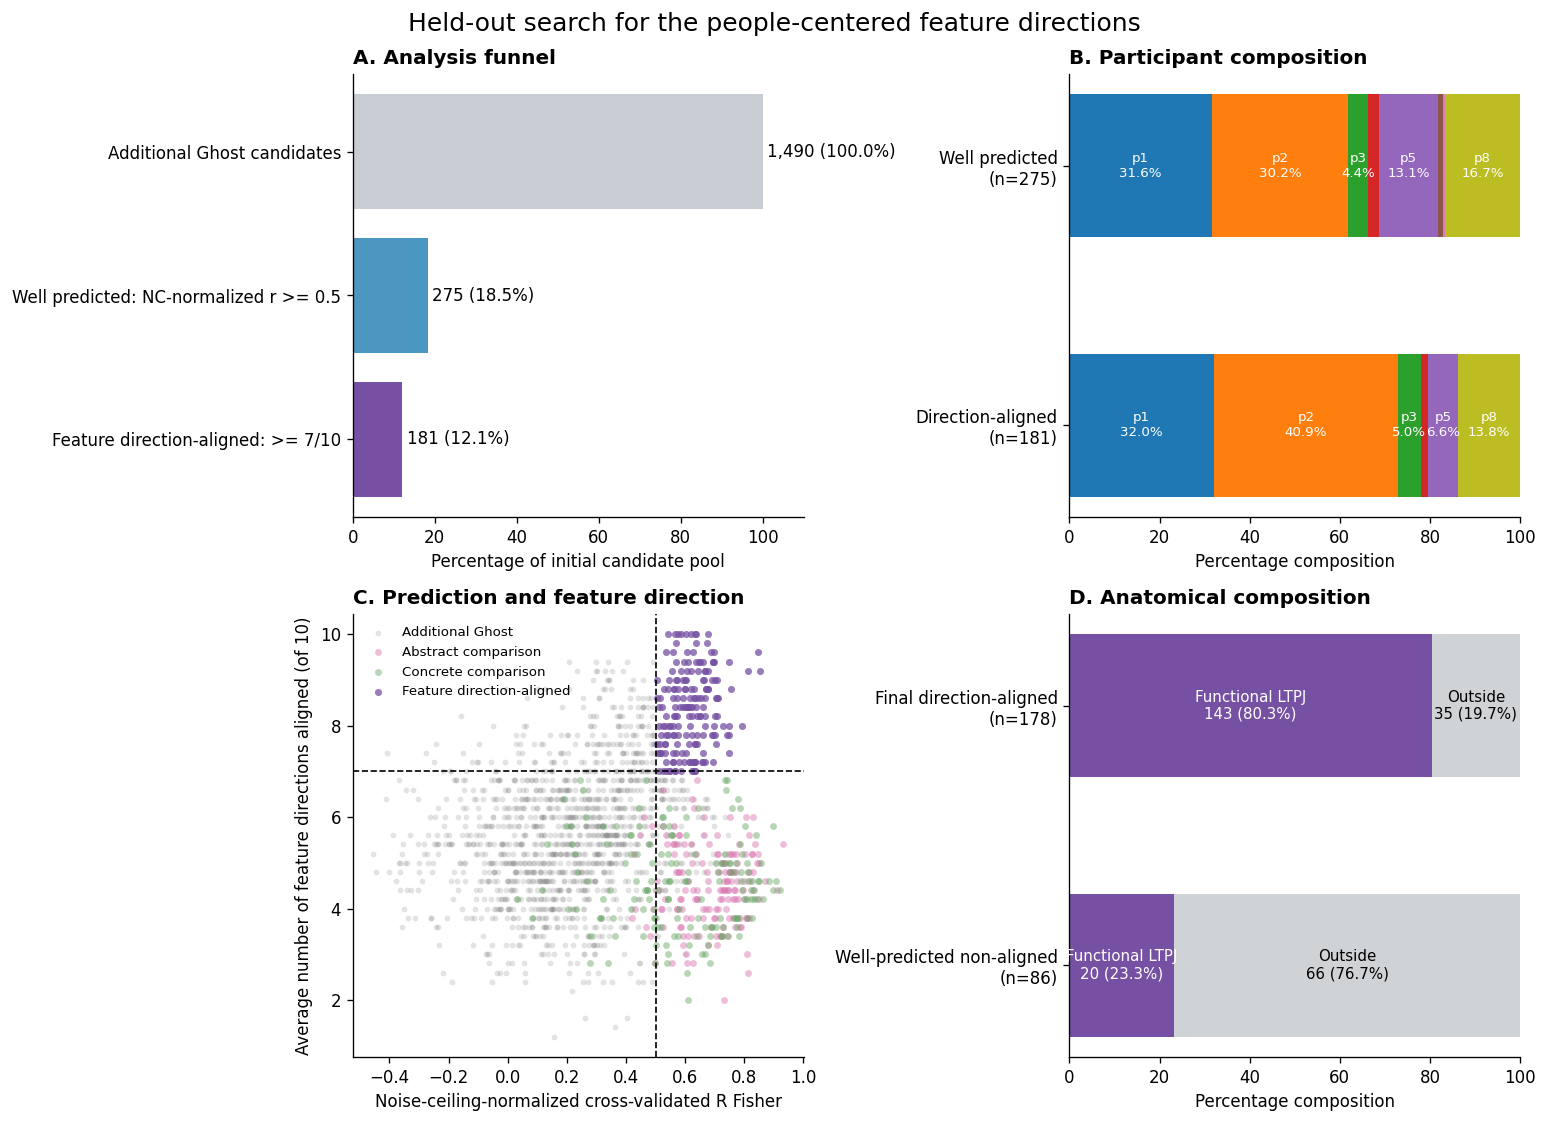

In [7]:
# Composition figure used to keep all denominators explicit.
participant_colors = dict(
    zip(PARTICIPANTS, plt.cm.tab10(np.linspace(0, 0.8, len(PARTICIPANTS))))
)
COLOR_POOL = "#C8CDD3"
COLOR_PREDICTED = "#4C97C2"
COLOR_ALIGNED = "#7651A3"
COLOR_OTHER = "#D0D3D6"

fig, axes = plt.subplots(2, 2, figsize=(13, 9.5))
ax_a, ax_b, ax_c, ax_d = axes.ravel()

# A: funnel
stage_counts = [len(ghost), len(well_predicted), len(aligned)]
stage_labels = [
    "Additional Ghost candidates",
    f"Well predicted: NC-normalized r >= {PREDICTION_THRESHOLD}",
    f"Feature direction-aligned: >= {DIRECTION_THRESHOLD:g}/10",
]
stage_percent = 100 * np.array(stage_counts) / len(ghost)
ax_a.barh(
    np.arange(3),
    stage_percent,
    color=[COLOR_POOL, COLOR_PREDICTED, COLOR_ALIGNED],
)
ax_a.set_yticks(np.arange(3), stage_labels)
ax_a.invert_yaxis()
ax_a.set_xlabel("Percentage of initial candidate pool")
for y, n, pct in zip(range(3), stage_counts, stage_percent):
    ax_a.text(pct + 1, y, f"{n:,} ({pct:.1f}%)", va="center")
ax_a.set_xlim(0, 110)
ax_a.set_title("A. Analysis funnel", loc="left", fontweight="bold")

# B: participant composition of the two retained sets
for y, (label, frame) in enumerate(
    [("Well predicted", well_predicted), ("Feature direction-aligned", aligned)]
):
    left = 0
    for participant in PARTICIPANTS:
        n = frame["Participant"].eq(participant).sum()
        pct = 100 * n / len(frame)
        ax_b.barh(
            y, pct, left=left, color=participant_colors[participant], height=0.55
        )
        if pct >= 4:
            ax_b.text(
                left + pct / 2,
                y,
                f"{participant}\n{pct:.1f}%",
                ha="center",
                va="center",
                fontsize=8,
                color="white",
            )
        left += pct
ax_b.set_yticks([0, 1], ["Well predicted\n(n=275)", "Direction-aligned\n(n=181)"])
ax_b.invert_yaxis()
ax_b.set_xlim(0, 100)
ax_b.set_xlabel("Percentage composition")
ax_b.set_title("B. Participant composition", loc="left", fontweight="bold")

# C: joint prediction and direction space, including comparison voxels
nonaligned = ghost.drop(aligned.index)
ax_c.scatter(
    nonaligned[PREDICTION_COLUMN],
    nonaligned["Average Num Features Agree Direction"],
    s=12,
    alpha=0.20,
    color="#777777",
    linewidths=0,
    label="Additional Ghost",
)
for dataset, color, label in [
    ("abstract", "#D870AD", "Abstract comparison"),
    ("concrete", "#63A65F", "Concrete comparison"),
]:
    frame = comparison[comparison["dataset"].eq(dataset)]
    ax_c.scatter(
        frame[PREDICTION_COLUMN],
        frame["Average Num Features Agree Direction"],
        s=17,
        alpha=0.45,
        color=color,
        linewidths=0,
        label=label,
    )
ax_c.scatter(
    aligned[PREDICTION_COLUMN],
    aligned["Average Num Features Agree Direction"],
    s=18,
    alpha=0.75,
    color=COLOR_ALIGNED,
    linewidths=0,
    label="Feature direction-aligned",
)
ax_c.axvline(PREDICTION_THRESHOLD, color="black", ls="--", lw=1)
ax_c.axhline(DIRECTION_THRESHOLD, color="black", ls="--", lw=1)
ax_c.set_xlabel("Noise-ceiling-normalized cross-validated R Fisher")
ax_c.set_ylabel("Average number of feature directions aligned (of 10)")
ax_c.legend(frameon=False, fontsize=8)
ax_c.set_title("C. Prediction and feature direction", loc="left", fontweight="bold")

# D: anatomical composition for the five contributing participants
for y, (label, frame) in enumerate(
    [
        ("Final feature direction-aligned", core_aligned),
        ("Well-predicted but non-aligned", core_well_nonaligned),
    ]
):
    inside_n = int(frame["Inside Saxe functional LTPJ"].sum())
    inside_pct = 100 * inside_n / len(frame)
    outside_n = len(frame) - inside_n
    outside_pct = 100 - inside_pct
    ax_d.barh(y, inside_pct, color=COLOR_ALIGNED, height=0.55)
    ax_d.barh(
        y,
        outside_pct,
        left=inside_pct,
        color=COLOR_OTHER,
        height=0.55,
    )
    ax_d.text(
        inside_pct / 2,
        y,
        f"Functional LTPJ\n{inside_n} ({inside_pct:.1f}%)",
        ha="center",
        va="center",
        fontsize=9,
        color="white",
    )
    ax_d.text(
        inside_pct + outside_pct / 2,
        y,
        f"Outside\n{outside_n} ({outside_pct:.1f}%)",
        ha="center",
        va="center",
        fontsize=9,
    )
ax_d.set_yticks(
    [0, 1],
    [
        f"Final direction-aligned\n(n={len(core_aligned)})",
        f"Well-predicted non-aligned\n(n={len(core_well_nonaligned)})",
    ],
)
ax_d.invert_yaxis()
ax_d.set_xlim(0, 100)
ax_d.set_xlabel("Percentage composition")
ax_d.set_title("D. Anatomical composition", loc="left", fontweight="bold")

fig.suptitle(
    "Held-out search for the people-centered feature directions",
    fontsize=15,
)
fig.tight_layout()
plt.show()

## Strict 10/10 feature-direction agreement

As a strict descriptive check, we identify voxels for which all 10 feature
directions agree in every cross-validation fold. This is intentionally stricter
than the primary 7/10 criterion and is not used to establish cross-participant
recurrence.

In [8]:
ten_of_ten = ghost[
    np.isclose(ghost["Average Num Features Agree Direction"], 10.0)
].copy()
ten_of_ten["Passes primary prediction threshold"] = (
    ten_of_ten[PREDICTION_COLUMN] >= PREDICTION_THRESHOLD
)
ten_of_ten = ten_of_ten.sort_values(PREDICTION_COLUMN, ascending=False)

ten_table = ten_of_ten[
    [
        "Participant",
        "neuroid",
        "R Fischer",
        "NC Normalized R Fischer",
        "R Fischer SEM",
        "Parcel Name",
        "Inside Saxe functional LTPJ",
        "Passes primary prediction threshold",
    ]
].reset_index(drop=True)
display(ten_table)

print(f"10/10-aligned voxels: {len(ten_of_ten)}")
print("Participants:", ten_of_ten["Participant"].value_counts().to_dict())
print("Parcels:", ten_of_ten["Parcel Name"].value_counts().to_dict())

assert len(ten_of_ten) == 9
assert set(ten_of_ten["Participant"]) == {"p2"}
assert set(ten_of_ten["Parcel Name"]) == {"PGi"}
assert ten_of_ten["Inside Saxe functional LTPJ"].all()
assert ten_of_ten["Passes primary prediction threshold"].all()

,Participant,neuroid,R Fischer,NC Normalized R Fischer,R Fischer SEM,Parcel Name,Inside Saxe functional LTPJ,Passes primary prediction threshold
0,p2,156812,0.395,0.678,0.039,PGi,True,True
1,p2,86301,0.413,0.636,0.039,PGi,True,True
2,p2,23268,0.415,0.632,0.028,PGi,True,True
3,p2,156816,0.358,0.618,0.018,PGi,True,True
4,p2,156801,0.413,0.603,0.037,PGi,True,True
5,p2,156800,0.406,0.584,0.048,PGi,True,True
6,p2,156797,0.392,0.577,0.054,PGi,True,True
7,p2,54139,0.386,0.564,0.046,PGi,True,True
8,p2,2686,0.368,0.543,0.046,PGi,True,True


10/10-aligned voxels: 9
Participants: {'p2': 9}
Parcels: {'PGi': 9}


In [9]:
# Response similarity among the nine strict voxels.
p2_ids = ten_of_ten["neuroid"].astype(int).tolist()
p2_betas = pd.read_csv(
    META_DIR / "p2" / "ghost_additional_betas.csv",
    index_col=0,
)
p2_columns = [str(neuroid) for neuroid in p2_ids]
strict_corr = p2_betas[p2_columns].corr()
upper = strict_corr.values[np.triu_indices(len(strict_corr), 1)]

print(
    "Pairwise response correlation among the nine 10/10 voxels: "
    f"median={np.median(upper):.3f}, "
    f"mean={np.mean(upper):.3f}, "
    f"range=({np.min(upper):.3f}, {np.max(upper):.3f})"
)
display(strict_corr.style.background_gradient(cmap="Purples", vmin=0, vmax=1))

Pairwise response correlation among the nine 10/10 voxels: median=0.859, mean=0.855, range=(0.667, 0.980)


,156812,86301,23268,156816,156801,156800,156797,54139,2686
156812,1.000000,0.924986,0.844052,0.666943,0.836759,0.789702,0.774224,0.759597,0.758358
86301,0.924986,1.000000,0.867347,0.749311,0.878739,0.850297,0.833107,0.821587,0.826318
23268,0.844052,0.867347,1.000000,0.770540,0.972159,0.940704,0.882747,0.940769,0.878211
156816,0.666943,0.749311,0.770540,1.000000,0.777659,0.754356,0.708320,0.732334,0.700644
156801,0.836759,0.878739,0.972159,0.777659,1.000000,0.973145,0.927245,0.931587,0.906970
156800,0.789702,0.850297,0.940704,0.754356,0.973145,1.000000,0.974588,0.969292,0.964575
156797,0.774224,0.833107,0.882747,0.708320,0.927245,0.974588,1.000000,0.934371,0.979899
54139,0.759597,0.821587,0.940769,0.732334,0.931587,0.969292,0.934371,1.000000,0.963117
2686,0.758358,0.826318,0.878211,0.700644,0.906970,0.964575,0.979899,0.963117,1.000000


All nine 10/10 voxels are well predicted, come from p2, and fall inside both
PGi and the independent functional LTPJ parcel. Their response profiles are
also strongly correlated. Perfect agreement
therefore identifies a particularly coherent p2–PGi group, but it does not
establish cross-participant recurrence. The 7/10 criterion is more appropriate
for the main question of whether the broader feature alignment occurs across
people.

## Supplement: robustness across prediction scales and thresholds

The primary analysis uses \(r_{\mathrm{NC}}\geq0.50\). To show that the
result does not depend on this exact cutoff, we repeat it at one lower
(\(0.40\)) and one higher (\(0.60\)) noise-ceiling-normalized threshold. We
also move the former raw-\(r\) analysis to this supplement and report the
original \(r\geq0.25\) rule with one lower (\(0.20\)) and one higher
(\(0.30\)) threshold.

The first table gives the number and percentage of candidate voxels that are
well predicted, and the number and percentage of those well-predicted voxels
that are feature direction-aligned. The second table gives functional LTPJ
overlap within the five primary contributing participants. Percentages in
that table are within the corresponding well-predicted or feature
direction-aligned set.

In [10]:
supplemental_rules = [
    {
        "Prediction scale": "NC-normalized R Fisher",
        "Column": "NC Normalized R Fischer",
        "Threshold": 0.40,
        "Role": "Lower",
    },
    {
        "Prediction scale": "NC-normalized R Fisher",
        "Column": "NC Normalized R Fischer",
        "Threshold": 0.50,
        "Role": "Primary",
    },
    {
        "Prediction scale": "NC-normalized R Fisher",
        "Column": "NC Normalized R Fischer",
        "Threshold": 0.60,
        "Role": "Higher",
    },
    {
        "Prediction scale": "Raw R Fisher",
        "Column": "R Fischer",
        "Threshold": 0.20,
        "Role": "Lower",
    },
    {
        "Prediction scale": "Raw R Fisher",
        "Column": "R Fischer",
        "Threshold": 0.25,
        "Role": "Former specification",
    },
    {
        "Prediction scale": "Raw R Fisher",
        "Column": "R Fischer",
        "Threshold": 0.30,
        "Role": "Higher",
    },
]

threshold_rows = []
ltpj_composition_rows = []
supplemental_sets = {}

for rule in supplemental_rules:
    scale = rule["Prediction scale"]
    column = rule["Column"]
    threshold = rule["Threshold"]
    role = rule["Role"]
    rule_key = (scale, threshold)

    threshold_well = ghost[ghost[column] >= threshold].copy()
    threshold_aligned = threshold_well[
        threshold_well["Average Num Features Agree Direction"]
        >= DIRECTION_THRESHOLD
    ].copy()
    supplemental_sets[rule_key] = (threshold_well, threshold_aligned)
    participant_counts = threshold_aligned["Participant"].value_counts()

    threshold_rows.append(
        {
            "Prediction scale": scale,
            "Threshold": threshold,
            "Role": role,
            "Well-predicted voxels": len(threshold_well),
            "Well-predicted candidates (%)": (
                100 * len(threshold_well) / len(ghost)
            ),
            "Feature direction-aligned voxels": len(threshold_aligned),
            "Aligned among well-predicted (%)": (
                100 * len(threshold_aligned) / len(threshold_well)
            ),
            "Participants with >3 aligned voxels": int(
                (participant_counts > MAX_LOW_CONTRIBUTION).sum()
            ),
        }
    )

    for set_name, frame in [
        ("Well predicted", threshold_well),
        ("Feature direction-aligned", threshold_aligned),
    ]:
        core_frame = frame[
            frame["Participant"].isin(ANATOMY_PARTICIPANTS)
        ]
        inside_n = int(core_frame["Inside Saxe functional LTPJ"].sum())
        ltpj_composition_rows.append({
            "Prediction scale": scale,
            "Threshold": threshold,
            "Role": role,
            "Voxel set": set_name,
            "Total voxels": len(core_frame),
            "Inside functional LTPJ n": inside_n,
            "Inside functional LTPJ (%)": (
                100 * inside_n / len(core_frame) if len(core_frame) else np.nan
            ),
        })

threshold_robustness = pd.DataFrame(threshold_rows)
display(
    threshold_robustness.style.format(
        {
            "Threshold": "{:.2f}",
            "Well-predicted candidates (%)": "{:.1f}",
            "Aligned among well-predicted (%)": "{:.1f}",
        }
    )
)

ltpj_robustness = pd.DataFrame(ltpj_composition_rows)
display(
    ltpj_robustness.style.format(
        {
            "Threshold": "{:.2f}",
            "Inside functional LTPJ (%)": "{:.1f}",
        }
    )
)

,Prediction scale,Threshold,Role,Well-predicted voxels,Well-predicted candidates (%),Feature direction-aligned voxels,Aligned among well-predicted (%),Participants with >3 aligned voxels
0,NC-normalized R Fisher,0.40,Lower,430,28.9,254,59.1,5
1,NC-normalized R Fisher,0.50,Primary,275,18.5,181,65.8,5
2,NC-normalized R Fisher,0.60,Higher,137,9.2,104,75.9,5
3,Raw R Fisher,0.20,Lower,565,37.9,290,51.3,5
4,Raw R Fisher,0.25,Former specification,415,27.9,245,59.0,5
5,Raw R Fisher,0.30,Higher,292,19.6,191,65.4,5


,Prediction scale,Threshold,Role,Voxel set,Total voxels,Inside functional LTPJ n,Inside functional LTPJ (%)
0,NC-normalized R Fisher,0.40,Lower,Well predicted,411,230,56.0
1,NC-normalized R Fisher,0.40,Lower,Feature direction-aligned,250,185,74.0
2,NC-normalized R Fisher,0.50,Primary,Well predicted,264,163,61.7
3,NC-normalized R Fisher,0.50,Primary,Feature direction-aligned,178,143,80.3
4,NC-normalized R Fisher,0.60,Higher,Well predicted,133,94,70.7
5,NC-normalized R Fisher,0.60,Higher,Feature direction-aligned,103,92,89.3
6,Raw R Fisher,0.20,Lower,Well predicted,538,276,51.3
7,Raw R Fisher,0.20,Lower,Feature direction-aligned,286,206,72.0
8,Raw R Fisher,0.25,Former specification,Well predicted,398,227,57.0
9,Raw R Fisher,0.25,Former specification,Feature direction-aligned,241,183,75.9


The result is stable on both prediction scales. Across the normalized
thresholds \(0.40\), \(0.50\), and \(0.60\), 254, 181, and 104 voxels are
feature direction-aligned across all participants; the functional LTPJ parcel
contains 74.0%, 80.3%, and 89.3% of the aligned voxels in the five primary
contributing participants. Across
raw thresholds \(0.20\), \(0.25\), and \(0.30\), 290, 245, and 191 voxels are
aligned across all participants, and the corresponding functional LTPJ
percentages are 72.0%, 75.9%, and 77.7%. The same five participants contribute
more than three aligned voxels under every specification.

## Robustness to the feature-direction threshold

Next, we hold the primary prediction threshold at
\(r_{\mathrm{NC}}\geq0.50\) and vary the required average directional
agreement. The comparison-voxel column shows how many Abstract or Concrete
voxels pass the same prediction and direction gates.

,Direction threshold,Feature direction-aligned voxels,Abstract/Concrete comparison voxels,Participants with >3 aligned voxels,Functional LTPJ among primary participants (%),p1,p2,p3,p4,p5,p6,p7,p8
0,6.0,229,19,6,71.7,70,82,11,6,24,3,1,32
1,6.5,202,5,6,78.9,65,77,9,5,14,2,1,29
2,7.0,181,0,5,80.3,58,74,9,3,12,0,0,25
3,7.5,143,0,5,82.9,42,73,7,3,7,0,0,11
4,8.0,118,0,4,81.0,28,71,7,2,7,0,0,3
5,8.5,80,0,3,86.1,10,63,2,1,4,0,0,0
6,9.0,52,0,1,94.1,2,48,0,1,1,0,0,0
7,9.5,19,0,1,94.7,0,19,0,0,0,0,0,0
8,10.0,9,0,1,100.0,0,9,0,0,0,0,0,0


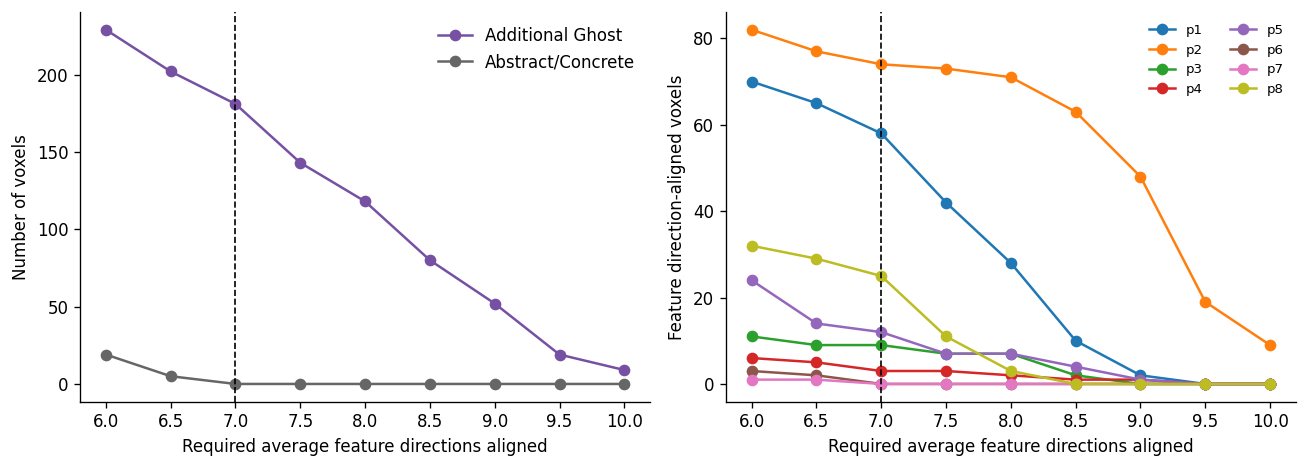

In [11]:
direction_thresholds = [6.0, 6.5, 7.0, 7.5, 8.0, 8.5, 9.0, 9.5, 10.0]
direction_robustness_rows = []

comparison_well = comparison[
    comparison[PREDICTION_COLUMN] >= PREDICTION_THRESHOLD
]
for threshold in direction_thresholds:
    threshold_aligned = well_predicted[
        well_predicted["Average Num Features Agree Direction"] >= threshold
    ]
    threshold_comparison = comparison_well[
        comparison_well["Average Num Features Agree Direction"] >= threshold
    ]
    participant_counts = threshold_aligned["Participant"].value_counts()
    threshold_core = threshold_aligned[
        threshold_aligned["Participant"].isin(ANATOMY_PARTICIPANTS)
    ]
    direction_robustness_rows.append(
        {
            "Direction threshold": threshold,
            "Feature direction-aligned voxels": len(threshold_aligned),
            "Abstract/Concrete comparison voxels": len(threshold_comparison),
            "Participants with >3 aligned voxels": int(
                (participant_counts > MAX_LOW_CONTRIBUTION).sum()
            ),
            "Functional LTPJ among primary participants (%)": (
                100
                * threshold_core["Inside Saxe functional LTPJ"].mean()
                if len(threshold_core)
                else np.nan
            ),
            **{
                participant: int(participant_counts.get(participant, 0))
                for participant in PARTICIPANTS
            },
        }
    )

direction_robustness = pd.DataFrame(direction_robustness_rows)
display(
    direction_robustness.style.format(
        {
            "Direction threshold": "{:.1f}",
            "Functional LTPJ among primary participants (%)": "{:.1f}",
        }
    )
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(
    direction_robustness["Direction threshold"],
    direction_robustness["Feature direction-aligned voxels"],
    marker="o",
    color=COLOR_ALIGNED,
    label="Additional Ghost",
)
axes[0].plot(
    direction_robustness["Direction threshold"],
    direction_robustness["Abstract/Concrete comparison voxels"],
    marker="o",
    color="#666666",
    label="Abstract/Concrete",
)
axes[0].axvline(DIRECTION_THRESHOLD, color="black", ls="--", lw=1)
axes[0].set_xlabel("Required average feature directions aligned")
axes[0].set_ylabel("Number of voxels")
axes[0].legend(frameon=False)

for participant in PARTICIPANTS:
    axes[1].plot(
        direction_robustness["Direction threshold"],
        direction_robustness[participant],
        marker="o",
        label=participant,
        color=participant_colors[participant],
    )
axes[1].axvline(DIRECTION_THRESHOLD, color="black", ls="--", lw=1)
axes[1].set_xlabel("Required average feature directions aligned")
axes[1].set_ylabel("Feature direction-aligned voxels")
axes[1].legend(frameon=False, ncol=2, fontsize=8)
fig.tight_layout()
plt.show()

The 7/10 criterion is a simple supermajority rule and is also the first
threshold at which no Abstract or Concrete comparison voxel remains. The same
five principal participants contribute more than three voxels through 7.5/10.
At 8/10, p8 falls to three voxels; at 9/10 and above, the result becomes
dominated by p2. At 10/10, all nine surviving voxels come from p2–PGi.

## Summary

- We searched 1,490 non-overlapping additional Ghost voxels using a fixed
  10-feature people-centered basis.
- 275 voxels passed the primary \(r_{\mathrm{NC}}\geq0.50\) prediction screen.
- 181 also had at least 7/10 feature directions aligned.
- Five participants contributed more than three aligned voxels; three
  participants together contributed only three.
- Within the five contributing participants, the independent functional LTPJ
  parcel contained 80.3% of feature direction-aligned voxels, compared with
  23.3% of well-predicted but non-aligned voxels and 29.0% of all additional
  Ghost candidates.
- The main participant and anatomical conclusions are stable across a broad
  range of raw, noise-ceiling-normalized, and direction thresholds; the
  supplement reports functional LTPJ overlap for each specification and
  retains the Glasser PGi/TPOJ analysis as a secondary anatomical reference.
- Perfect 10/10 agreement is a strict p2 phenomenon inside functional LTPJ and
  is therefore a useful descriptive subset, not the primary cross-participant
  criterion.

## Exact fsaverage7 vertex overlap across participants

Because all participants are represented on the same left-hemisphere
fsaverage7 mesh, `neuroid` is directly comparable as a surface-vertex index.
We therefore ask how often the **exact same vertex ID** appears in more than
one participant at three stages: the full additional Ghost candidate pool,
the well-predicted set, and the feature direction-aligned set.

This is deliberately an exact-index audit; it does not treat nearby vertices
as overlapping and does not apply spatial smoothing. Candidate eligibility is
participant-specific, so low exact overlap can reflect both anatomical or
functional variability and differences in which vertices entered each
participant's candidate pool.

,Analysis stage,Participant–vertex observations,Unique vertex IDs,IDs in >=2 participants,Shared IDs among unique IDs (%),Maximum participants at one ID
0,All additional Ghost candidates,1490,1474,16,1.09,2
1,Well predicted,275,270,5,1.85,2
2,Feature direction-aligned,181,178,3,1.69,2


,Analysis stage,Participant pair,Shared exact vertex IDs,Jaccard overlap (%)
0,All additional Ghost candidates,p1–p2,5,0.59
1,All additional Ghost candidates,p1–p4,4,0.51
2,All additional Ghost candidates,p1–p5,1,0.12
3,All additional Ghost candidates,p1–p8,1,0.12
4,All additional Ghost candidates,p2–p3,1,0.35
5,All additional Ghost candidates,p2–p5,1,0.26
6,All additional Ghost candidates,p2–p8,2,0.56
7,All additional Ghost candidates,p5–p6,1,0.45
8,Well predicted,p1–p2,4,2.41
9,Well predicted,p2–p3,1,1.06


,neuroid,Participant,Parcel Name,NC Normalized R Fischer,Average Num Features Agree Direction
0,11418,p1,PGi,0.563,7.8
1,11418,p2,PGi,0.568,9.0
2,42139,p1,PGi,0.629,8.6
3,42139,p2,PGi,0.603,9.0
4,120150,p1,PGi,0.615,8.0
5,120150,p2,PGi,0.583,8.4


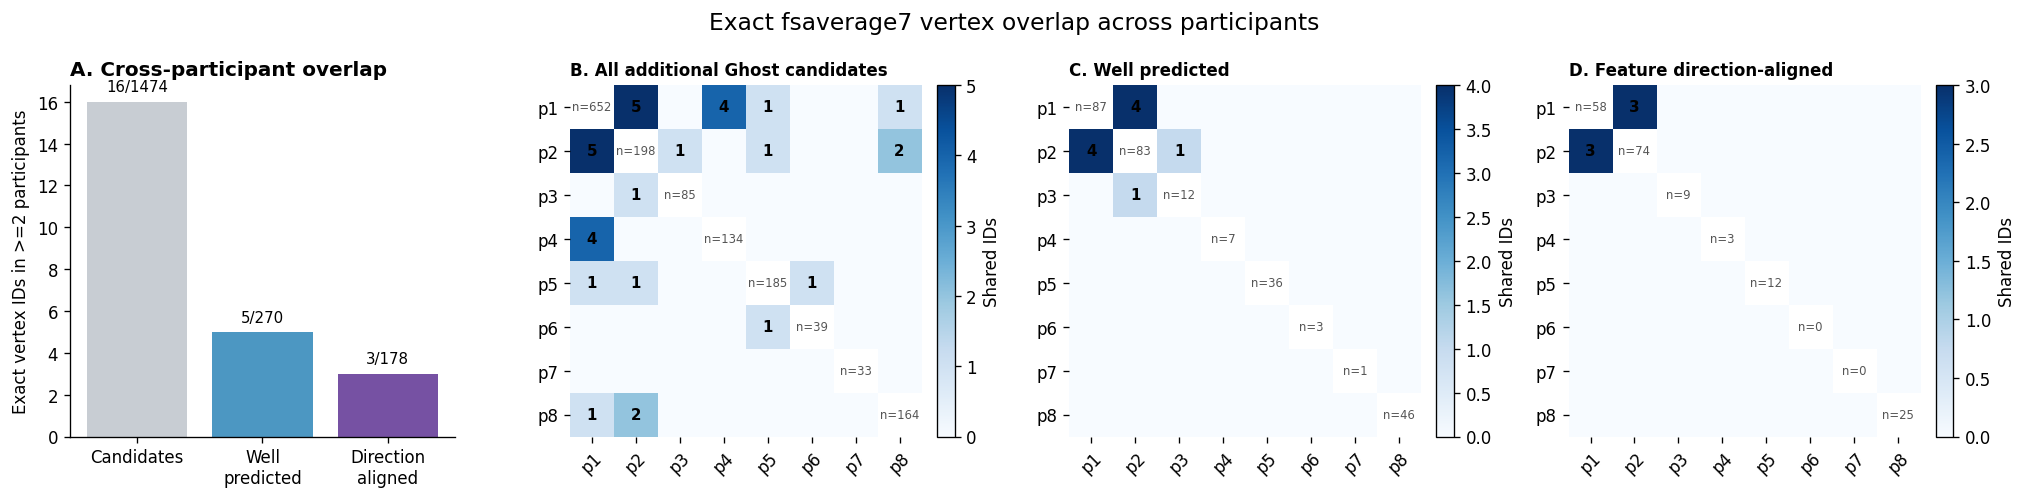

In [12]:
overlap_sets = {
    "All additional Ghost candidates": ghost,
    "Well predicted": well_predicted,
    "Feature direction-aligned": aligned,
}


def exact_vertex_overlap(frame):
    participant_sets = {
        participant: set(
            frame.loc[frame["Participant"].eq(participant), "neuroid"].astype(int)
        )
        for participant in PARTICIPANTS
    }
    multiplicity = frame.groupby("neuroid")["Participant"].nunique()
    counts = pd.DataFrame(0, index=PARTICIPANTS, columns=PARTICIPANTS, dtype=int)
    jaccard = pd.DataFrame(
        0.0, index=PARTICIPANTS, columns=PARTICIPANTS, dtype=float
    )
    for participant_a in PARTICIPANTS:
        for participant_b in PARTICIPANTS:
            set_a = participant_sets[participant_a]
            set_b = participant_sets[participant_b]
            intersection = len(set_a & set_b)
            union = len(set_a | set_b)
            counts.loc[participant_a, participant_b] = intersection
            jaccard.loc[participant_a, participant_b] = (
                100 * intersection / union if union else np.nan
            )
    return participant_sets, multiplicity, counts, jaccard


overlap_audits = {
    name: exact_vertex_overlap(frame) for name, frame in overlap_sets.items()
}

overlap_rows = []
for name, frame in overlap_sets.items():
    _, multiplicity, _, _ = overlap_audits[name]
    shared = multiplicity[multiplicity >= 2]
    overlap_rows.append(
        {
            "Analysis stage": name,
            "Participant–vertex observations": len(frame),
            "Unique vertex IDs": len(multiplicity),
            "IDs in >=2 participants": len(shared),
            "Shared IDs among unique IDs (%)": (
                100 * len(shared) / len(multiplicity)
            ),
            "Maximum participants at one ID": int(multiplicity.max()),
        }
    )

exact_overlap_summary = pd.DataFrame(overlap_rows)
display(
    exact_overlap_summary.style.format(
        {"Shared IDs among unique IDs (%)": "{:.2f}"}
    )
)

# Report every non-zero between-participant intersection and its Jaccard rate.
pairwise_rows = []
for name, (_, _, counts, jaccard) in overlap_audits.items():
    for index_a, participant_a in enumerate(PARTICIPANTS):
        for participant_b in PARTICIPANTS[index_a + 1:]:
            overlap_n = int(counts.loc[participant_a, participant_b])
            if overlap_n:
                pairwise_rows.append(
                    {
                        "Analysis stage": name,
                        "Participant pair": f"{participant_a}–{participant_b}",
                        "Shared exact vertex IDs": overlap_n,
                        "Jaccard overlap (%)": jaccard.loc[
                            participant_a, participant_b
                        ],
                    }
                )
pairwise_exact_overlap = pd.DataFrame(pairwise_rows)
display(pairwise_exact_overlap.style.format({"Jaccard overlap (%)": "{:.2f}"}))

# Inspect the exact vertices shared in the final aligned set.
aligned_multiplicity = overlap_audits["Feature direction-aligned"][1]
shared_aligned_ids = aligned_multiplicity[
    aligned_multiplicity >= 2
].index.astype(int)
shared_aligned_details = (
    aligned.loc[
        aligned["neuroid"].astype(int).isin(shared_aligned_ids),
        [
            "neuroid",
            "Participant",
            "Parcel Name",
            "NC Normalized R Fischer",
            "Average Num Features Agree Direction",
        ],
    ]
    .sort_values(["neuroid", "Participant"])
    .reset_index(drop=True)
)
display(shared_aligned_details)

# Visualization: overall shared-ID counts plus off-diagonal pairwise overlaps.
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2))

stage_labels = ["Candidates", "Well\npredicted", "Direction\naligned"]
shared_counts = exact_overlap_summary["IDs in >=2 participants"].to_numpy()
unique_counts = exact_overlap_summary["Unique vertex IDs"].to_numpy()
bars = axes[0].bar(
    stage_labels,
    shared_counts,
    color=[COLOR_POOL, COLOR_PREDICTED, COLOR_ALIGNED],
)
axes[0].set_ylabel("Exact vertex IDs in >=2 participants")
axes[0].set_title("A. Cross-participant overlap", loc="left", fontweight="bold")
for bar, shared_n, unique_n in zip(bars, shared_counts, unique_counts):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        shared_n + 0.35,
        f"{shared_n}/{unique_n}",
        ha="center",
        va="bottom",
        fontsize=9,
    )
axes[0].spines[["top", "right"]].set_visible(False)

for ax, (name, (_, _, counts, _)), panel in zip(
    axes[1:], overlap_audits.items(), ["B", "C", "D"]
):
    off_diagonal = counts.to_numpy(dtype=float)
    diagonal_sizes = np.diag(off_diagonal).astype(int).copy()
    np.fill_diagonal(off_diagonal, np.nan)
    masked = np.ma.masked_invalid(off_diagonal)
    finite = off_diagonal[np.isfinite(off_diagonal)]
    vmax = max(1, int(finite.max()))
    image = ax.imshow(masked, cmap="Blues", vmin=0, vmax=vmax)
    ax.set_xticks(range(len(PARTICIPANTS)), PARTICIPANTS, rotation=45)
    ax.set_yticks(range(len(PARTICIPANTS)), PARTICIPANTS)
    ax.set_title(f"{panel}. {name}", loc="left", fontweight="bold", fontsize=10)
    for row in range(len(PARTICIPANTS)):
        for column in range(len(PARTICIPANTS)):
            if row == column:
                ax.text(
                    column,
                    row,
                    f"n={diagonal_sizes[row]}",
                    ha="center",
                    va="center",
                    fontsize=7,
                    color="#555555",
                )
            elif counts.iloc[row, column] > 0:
                ax.text(
                    column,
                    row,
                    str(int(counts.iloc[row, column])),
                    ha="center",
                    va="center",
                    fontsize=9,
                    fontweight="bold",
                )
    for spine in ax.spines.values():
        spine.set_visible(False)
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04, label="Shared IDs")

fig.suptitle("Exact fsaverage7 vertex overlap across participants", fontsize=14)
fig.tight_layout()
plt.show()

### Implication for a participant-aggregated surface figure

Exact vertex overlap is rare. The 1,490 candidate observations correspond to
1,474 unique vertex IDs, only 16 of which occur in two participants. The 181
feature direction-aligned observations correspond to 178 unique IDs: only
three IDs occur in two participants, and no ID occurs in more than two.
Those three shared aligned IDs are vertices **11418, 42139, and 120150**; each
is shared by p1 and p2 and labeled PGi in both participants.

Consequently, a pooled map colored by the number of participants at the exact
same vertex would be nearly binary and would understate cross-participant
anatomical convergence. The most faithful primary display is therefore a set
of participant-level maps in the common fsaverage7 space. A pooled map can
still be useful as a spatial-density visualization, provided that it is
described as anatomical concentration rather than exact vertexwise overlap.

## Surface visualization and anatomical references

The metadata's `neuroid` value indexes a vertex on the common left-hemisphere
fsaverage7 surface (163,842 vertices per hemisphere). This allows participant
voxels to be displayed in a common coordinate system, although a pooled map
is a spatial overlay rather than a conventional group-average activation map.

The **primary anatomical reference** is the independently defined probabilistic
functional LTPJ parcel. The five left-hemisphere language parcels are also
outlined: IFGorb, IFG, MFG, anterior temporal, and posterior temporal. No
anatomical label entered voxel selection, prediction screening, or feature-
direction scoring. The anatomical Glasser PGi/TPOJ1/2/3 definition is retained
only as a supplement.

All quantitative surface maps use one visual specification: Ghost candidates
below the prediction threshold are gray, while well-predicted voxels are
colored with `plasma` according to their graded feature-direction agreement.
Every voxel marker has the same area.

In [13]:
import base64
import gzip
import struct
import sys
import urllib.request
import xml.etree.ElementTree as ET
import zlib

from matplotlib.cm import ScalarMappable
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D


plt.rcParams.update({
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "font.size": 11,
    "axes.labelsize": 13,
    "axes.titlesize": 13,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
})

GLASSER_PATH = SURFACE_ASSET_DIR / "lh.HCP_MMP1_fsaverage.mgz"
GLASSER_LOOKUP_PATH = SURFACE_ASSET_DIR / "HCP_MMP1_fsaverage.txt"

LANGUAGE_SN8_PATH = (
    SURFACE_ASSET_DIR / "lh.parcels_language_fsaverage_frontal_SN8.gii"
)
LANGUAGE_SN220_PATH = (
    SURFACE_ASSET_DIR / "lh.parcels_language_fsaverage_REGULARIZED.gii"
)
LANGUAGE_PARCEL_NAMES = {
    1: "IFGorb",
    2: "IFG",
    3: "MFG",
    4: "AntTemp",
    5: "PostTemp",
}
LANGUAGE_OUTLINE_COLOR = "#555B61"

INFLATED_PATH = SURFACE_ASSET_DIR / "lh.inflated"
SULC_PATH = SURFACE_ASSET_DIR / "lh.sulc"
SURFACE_URLS = {
    INFLATED_PATH: (
        "https://natural-scenes-dataset.s3.amazonaws.com/"
        "nsddata/freesurfer/fsaverage/surf/lh.inflated"
    ),
    SULC_PATH: (
        "https://natural-scenes-dataset.s3.amazonaws.com/"
        "nsddata/freesurfer/fsaverage/surf/lh.sulc"
    ),
}


def ensure_surface_assets():
    SURFACE_ASSET_DIR.mkdir(parents=True, exist_ok=True)
    for path, url in SURFACE_URLS.items():
        if not path.exists():
            print(f"Downloading {path.name} from the NSD fsaverage release...")
            urllib.request.urlretrieve(url, path)


def read_fs_surface(path):
    with open(path, "rb") as handle:
        magic = int.from_bytes(handle.read(3), byteorder="big")
        if magic != 16_777_214:
            raise ValueError(f"Unexpected FreeSurfer surface magic: {magic}")
        handle.readline()
        handle.readline()
        n_vertices, n_faces = np.fromfile(handle, dtype=">i4", count=2)
        coordinates = np.fromfile(
            handle, dtype=">f4", count=int(n_vertices) * 3
        ).reshape(int(n_vertices), 3)
        faces = np.fromfile(
            handle, dtype=">i4", count=int(n_faces) * 3
        ).reshape(int(n_faces), 3)
    return coordinates.astype(float), faces.astype(int)


def read_fs_morph(path):
    with open(path, "rb") as handle:
        magic = int.from_bytes(handle.read(3), byteorder="big")
        if magic != 16_777_215:
            raise ValueError(f"Unexpected FreeSurfer morph magic: {magic}")
        n_vertices, _, values_per_vertex = np.fromfile(
            handle, dtype=">i4", count=3
        )
        values = np.fromfile(
            handle,
            dtype=">f4",
            count=int(n_vertices) * int(values_per_vertex),
        )
    return values.reshape(int(n_vertices), int(values_per_vertex)).squeeze()


def read_mgh_labels(path):
    with gzip.open(path, "rb") as handle:
        payload = handle.read()
    _, width, height, depth, frames, mgh_type, _ = struct.unpack(
        ">7i", payload[:28]
    )
    if mgh_type != 3:
        raise ValueError(f"Expected MGH float type 3, found {mgh_type}")
    n_values = width * height * depth * frames
    return np.frombuffer(
        payload, dtype=">f4", count=n_values, offset=284
    ).astype(int)


def read_surface_gifti(path):
    return read_gifti_float_array(path)


def load_optional_glasser(labels_path, lookup_path, parcel_names, n_vertices=163_842):
    missing = [path.name for path in (labels_path, lookup_path) if not path.is_file()]
    if missing:
        print(
            "Optional Glasser assets unavailable (" + ", ".join(missing) + "). "
            "Skipping Glasser surface outlines and file-dependent comparisons; "
            "primary LTPJ analyses and existing metadata summaries are unchanged."
        )
        return None, []
    labels = read_mgh_labels(labels_path)
    if labels.shape != (n_vertices,):
        raise ValueError("Unexpected Glasser surface shape")
    lookup = pd.read_csv(lookup_path, sep=r"\s+", names=["Parcel ID", "Parcel Name"])
    parcel_ids = lookup.loc[
        lookup["Parcel Name"].isin(parcel_names), "Parcel ID"
    ].astype(int).tolist()
    return np.isin(labels, parcel_ids), parcel_ids


ensure_surface_assets()
surface_coordinates, surface_faces = read_fs_surface(INFLATED_PATH)
surface_sulc = read_fs_morph(SULC_PATH)
language_sn8_labels = read_surface_gifti(LANGUAGE_SN8_PATH).astype(int)
language_sn220_labels = read_surface_gifti(LANGUAGE_SN220_PATH).astype(int)
saxe_ltpj_surface = validate_binary_surface(read_surface_gifti(SAXE_LTPJ_PATH))

assert surface_coordinates.shape == (163_842, 3)
assert surface_sulc.shape == (163_842,)
assert saxe_ltpj_surface.shape == (163_842,)
assert int(saxe_ltpj_surface.sum()) == 6_587
np.testing.assert_array_equal(saxe_ltpj_surface, saxe_ltpj)

glasser_tpj_surface, target_glasser_ids = load_optional_glasser(
    GLASSER_PATH, GLASSER_LOOKUP_PATH, PGI_TPOJ
)
GLASSER_AVAILABLE = glasser_tpj_surface is not None

# Reconstruct the five-parcel surface definition and validate its assignments
# on the released, selected language-fROI subset (not all surface vertices).
language_parcel_labels = np.zeros(163_842, dtype=int)
for parcel_id in (1, 2, 3):
    language_parcel_labels[language_sn8_labels == parcel_id] = parcel_id
for parcel_id in (4, 5):
    language_parcel_labels[language_sn220_labels == parcel_id] = parcel_id

language_checks = []
for participant in PARTICIPANTS:
    meta = pd.read_csv(META_DIR / participant / "langfroi12345_meta.csv")
    vertices = validated_vertices(meta["neuroid_id"])
    exact = language_parcel_labels[vertices] == meta["parc_lang"].to_numpy()
    language_checks.append((participant, len(exact), int(exact.sum())))
assert all(total == exact for _, total, exact in language_checks)
print("Surface assets loaded; language-parcel assignments match the released language-fROI subset.")
print("Probabilistic functional LTPJ vertices:", int(saxe_ltpj_surface.sum()))
if GLASSER_AVAILABLE:
    print("Glasser supplement labels:", target_glasser_ids)


Optional Glasser assets unavailable (lh.HCP_MMP1_fsaverage.mgz, HCP_MMP1_fsaverage.txt). Skipping Glasser surface outlines and file-dependent comparisons; primary LTPJ analyses and existing metadata summaries are unchanged.
Surface assets loaded; language-parcel assignments match the released language-fROI subset.
Probabilistic functional LTPJ vertices: 6587


In [14]:
# Project the inflated fsaverage7 surface into lateral and medial views.
face_coordinates = surface_coordinates[surface_faces]
face_normal_x = np.cross(
    face_coordinates[:, 1] - face_coordinates[:, 0],
    face_coordinates[:, 2] - face_coordinates[:, 0],
)[:, 0]

view_geometry = {}
for view, faces, x_coordinates in [
    ("lateral", surface_faces[face_normal_x < 0], -surface_coordinates[:, 1]),
    ("medial", surface_faces[face_normal_x > 0], surface_coordinates[:, 1]),
]:
    vertices = np.unique(faces)
    visible = np.zeros(163_842, dtype=bool)
    visible[vertices] = True
    edges = np.concatenate(
        [faces[:, [0, 1]], faces[:, [1, 2]], faces[:, [2, 0]]], axis=0
    )
    unique_edges, edge_counts = np.unique(
        np.sort(edges, axis=1), axis=0, return_counts=True
    )
    rim_edges = unique_edges[edge_counts == 1]
    view_geometry[view] = {
        "faces": faces,
        "vertices": vertices,
        "visible": visible,
        "edges": unique_edges,
        "rim_edges": rim_edges,
        "x": x_coordinates,
        "y": surface_coordinates[:, 2],
    }


def segments_from_edges(edges, x_coordinates, y_coordinates):
    return np.stack(
        [
            np.column_stack(
                [x_coordinates[edges[:, 0]], y_coordinates[edges[:, 0]]]
            ),
            np.column_stack(
                [x_coordinates[edges[:, 1]], y_coordinates[edges[:, 1]]]
            ),
        ],
        axis=1,
    )


def mask_boundary_segments(mask, view):
    geometry = view_geometry[view]
    edges = geometry["edges"]
    boundary = edges[mask[edges[:, 0]] != mask[edges[:, 1]]]
    return segments_from_edges(boundary, geometry["x"], geometry["y"])


for view, geometry in view_geometry.items():
    geometry["rim_segments"] = segments_from_edges(
        geometry["rim_edges"], geometry["x"], geometry["y"]
    )
    geometry["saxe_segments"] = mask_boundary_segments(
        saxe_ltpj_surface, view
    )
    if GLASSER_AVAILABLE:
        geometry["glasser_segments"] = mask_boundary_segments(
            glasser_tpj_surface, view
        )
    geometry["language_segments"] = {
        parcel_id: mask_boundary_segments(
            language_parcel_labels == parcel_id, view
        )
        for parcel_id in LANGUAGE_PARCEL_NAMES
    }

TPJ_OUTLINE_COLOR = "#111111"
GRAY_GHOST = "#9EA4AD"
agreement_cmap = plt.get_cmap("plasma")
agreement_norm = Normalize(vmin=0, vmax=10)
AGREEMENT_COLUMN = "Average Num Features Agree Direction"
MARKER_AREA = 24


def prepare_brain_axis(
    ax, view, reference="saxe", title=None, show_language=True
):
    if reference == "glasser" and not GLASSER_AVAILABLE:
        raise ValueError("Glasser outlines require the optional Glasser assets")
    geometry = view_geometry[view]
    vertices = geometry["vertices"]
    x_coordinates, y_coordinates = geometry["x"], geometry["y"]

    # Stronger sulcal/gyri contrast than the exploratory figures, while
    # preserving a neutral white/gray surface beneath the quantitative layer.
    lightness = np.interp(
        np.clip(surface_sulc[vertices], -1.5, 1.5),
        [-1.5, 1.5],
        [0.38, 0.995],
    )
    colors = np.column_stack(
        [lightness, lightness, lightness, np.ones_like(lightness)]
    )
    ax.scatter(
        x_coordinates[vertices],
        y_coordinates[vertices],
        color=colors,
        s=0.23,
        linewidths=0,
        rasterized=True,
        zorder=0,
    )
    ax.add_collection(
        LineCollection(
            geometry["rim_segments"],
            colors="#AEB4BA",
            linewidths=0.70,
            alpha=0.95,
            zorder=1,
        )
    )

    if show_language:
        for segments in geometry["language_segments"].values():
            ax.add_collection(
                LineCollection(
                    segments,
                    colors=LANGUAGE_OUTLINE_COLOR,
                    linewidths=0.62,
                    linestyles="solid",
                    alpha=0.78,
                    zorder=6,
                )
            )

    reference_segments = geometry[
        "saxe_segments" if reference == "saxe" else "glasser_segments"
    ]
    ax.add_collection(
        LineCollection(
            reference_segments,
            colors=TPJ_OUTLINE_COLOR,
            linewidths=2.65,
            alpha=0.98,
            zorder=7,
        )
    )

    ax.set_aspect("equal")
    ax.set_xlim(x_coordinates[vertices].min() - 3,
                x_coordinates[vertices].max() + 3)
    ax.set_ylim(y_coordinates[vertices].min() - 3,
                y_coordinates[vertices].max() + 3)
    ax.axis("off")
    if title:
        ax.set_title(title, fontsize=14, fontweight="bold", pad=2)


def plot_gray_and_agreement(ax, frame, view):
    geometry = view_geometry[view]
    visible = geometry["visible"]
    x_coordinates, y_coordinates = geometry["x"], geometry["y"]

    gray = frame[~frame["Well predicted"]]
    gray_vertices = gray["neuroid"].astype(int).to_numpy()
    gray_vertices = gray_vertices[visible[gray_vertices]]
    ax.scatter(
        x_coordinates[gray_vertices],
        y_coordinates[gray_vertices],
        s=MARKER_AREA,
        color=GRAY_GHOST,
        alpha=0.46,
        edgecolors="white",
        linewidths=0.18,
        rasterized=True,
        zorder=2,
    )

    predicted = frame[frame["Well predicted"]].copy()
    predicted = predicted[
        visible[predicted["neuroid"].astype(int).to_numpy()]
    ].sort_values(AGREEMENT_COLUMN)
    vertices = predicted["neuroid"].astype(int).to_numpy()
    ax.scatter(
        x_coordinates[vertices],
        y_coordinates[vertices],
        c=predicted[AGREEMENT_COLUMN],
        cmap=agreement_cmap,
        norm=agreement_norm,
        s=MARKER_AREA,
        alpha=0.74,
        edgecolors="#202124",
        linewidths=0.20,
        rasterized=True,
        zorder=3,
    )


def reference_legend(reference, show_language=True):
    label = (
        "Probabilistic functional LTPJ"
        if reference == "saxe"
        else "Glasser PGi/TPOJ1/2/3"
    )
    handles = [
        Line2D(
            [0], [0], marker="o", linestyle="none", color=GRAY_GHOST,
            label="Not well predicted", markersize=6,
        ),
        Line2D(
            [0], [0], color=TPJ_OUTLINE_COLOR, linewidth=2.65, label=label
        ),
    ]
    if show_language:
        handles.append(
            Line2D(
                [0], [0], color=LANGUAGE_OUTLINE_COLOR,
                linewidth=0.9, linestyle="solid", label="Language parcels",
            )
        )
    return handles


def add_agreement_colorbar(fig, axes, bounds=None):
    mappable = ScalarMappable(norm=agreement_norm, cmap=agreement_cmap)
    mappable.set_array([])
    if bounds is None:
        colorbar = fig.colorbar(
            mappable,
            ax=axes,
            orientation="horizontal",
            fraction=0.045,
            pad=0.035,
            aspect=52,
            ticks=[0, 2, 4, 6, 7, 8, 10],
        )
    else:
        colorbar_axis = fig.add_axes(bounds)
        colorbar = fig.colorbar(
            mappable,
            cax=colorbar_axis,
            orientation="horizontal",
            ticks=[0, 2, 4, 6, 7, 8, 10],
        )
    colorbar.set_label(
        "Mean feature directions matching the original signature (of 10)",
        fontsize=13,
        labelpad=6,
    )
    colorbar.ax.tick_params(labelsize=12, colors="black")
    colorbar.ax.axvline(7, color="white", linewidth=3.0)
    colorbar.ax.axvline(7, color="black", linewidth=1.2)
    colorbar.ax.text(
        7, 1.45, "7/10 cutoff", ha="center", va="bottom",
        fontsize=10, fontweight="bold",
    )
    return colorbar


def save_figure(fig, stem, dpi=350):
    Path(stem).parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(f"{stem}.png", dpi=dpi, bbox_inches="tight")
    fig.savefig(f"{stem}.pdf", bbox_inches="tight")
    print(f"Saved {Path(stem).name}.png and .pdf")


## Primary group surface map

The group map retains all 1,490 additional Ghost candidates. The 1,215 voxels
below the prediction threshold are gray. The 275 well-predicted voxels are
colored by their continuous feature-direction agreement, with the reported
7/10 cutoff marked on the colorbar. The probabilistic functional LTPJ and five
language parcels are reference outlines only; parcel numbers are intentionally
omitted.

Saved ghost_surface_agreement_plasma_functional_ltpj_primary_2026-09-22.png and .pdf


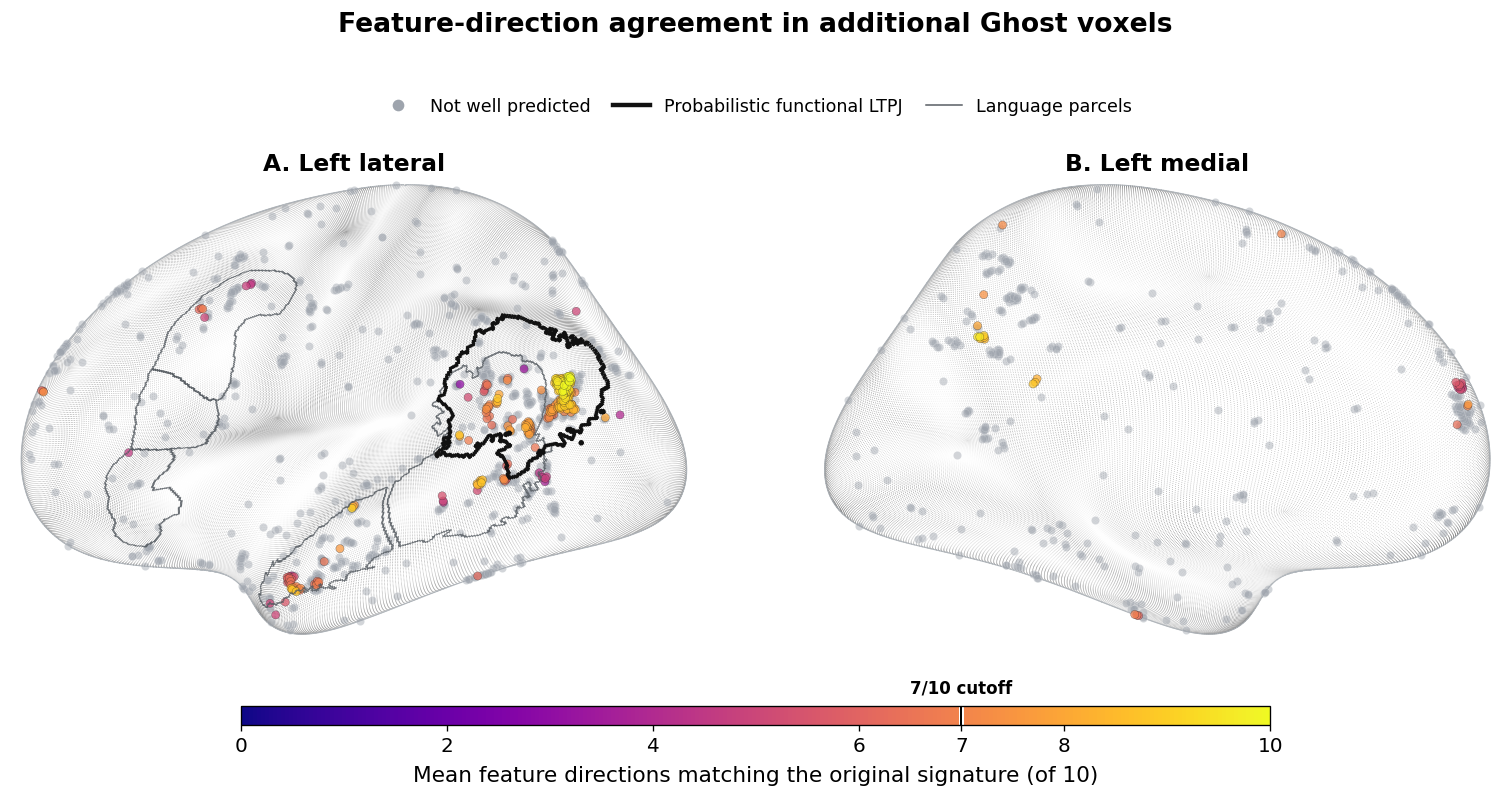

Saved ghost_surface_agreement_plasma_functional_ltpj_no_language_parcels_2026-09-22.png and .pdf


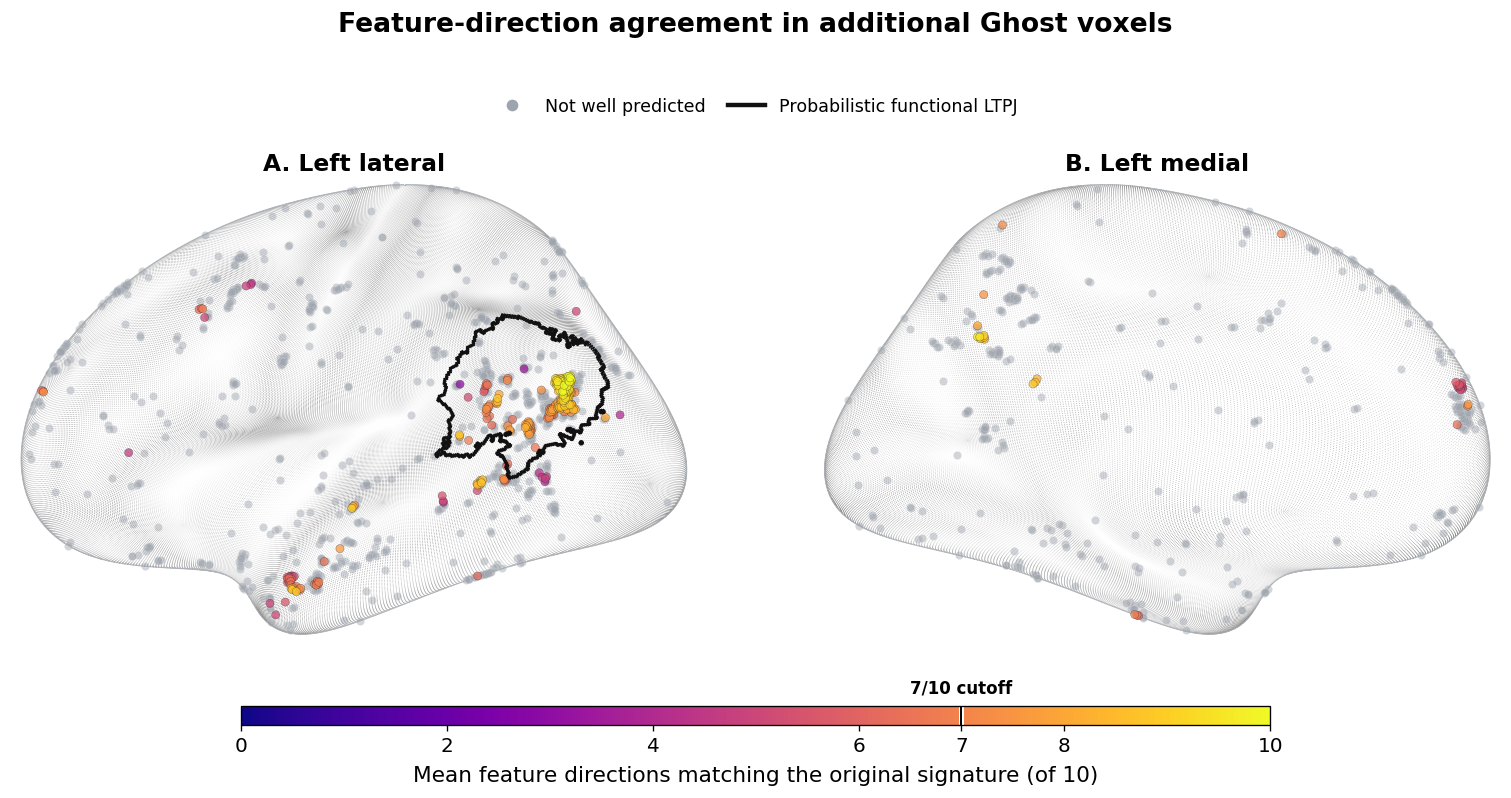

In [15]:
def make_group_surface(
    reference, title, output_stem, show_language=True
):
    fig, axes = plt.subplots(1, 2, figsize=(13.4, 6.5))
    for ax, view, panel in zip(
        axes,
        ["lateral", "medial"],
        ["A. Left lateral", "B. Left medial"],
    ):
        prepare_brain_axis(
            ax,
            view,
            reference=reference,
            title=panel,
            show_language=show_language,
        )
        plot_gray_and_agreement(ax, ghost, view)

    fig.subplots_adjust(
        left=0.01, right=0.99, top=0.78, bottom=0.18, wspace=0.04
    )
    add_agreement_colorbar(fig, axes, bounds=[0.18, 0.075, 0.64, 0.025])
    fig.legend(
        handles=reference_legend(reference, show_language=show_language),
        loc="upper center",
        bbox_to_anchor=(0.5, 0.90),
        frameon=False,
        ncol=4,
        fontsize=10.5,
        columnspacing=1.3,
        handlelength=2.1,
    )
    fig.suptitle(title, fontsize=16, fontweight="bold", y=0.99)
    save_figure(fig, output_stem)
    plt.show()


primary_surface_stem = (
    REPO_ROOT
    / "analysis/figures/ghost_surface_agreement_plasma_"
      "functional_ltpj_primary_2026-09-22"
)
make_group_surface(
    "saxe",
    "Feature-direction agreement in additional Ghost voxels",
    primary_surface_stem,
)

primary_surface_no_language_stem = (
    REPO_ROOT
    / "analysis/figures/ghost_surface_agreement_plasma_"
      "functional_ltpj_no_language_parcels_2026-09-22"
)
make_group_surface(
    "saxe",
    "Feature-direction agreement in additional Ghost voxels",
    primary_surface_no_language_stem,
    show_language=False,
)


## Primary anatomical quantification

The surface map is descriptive; the compact plots below quantify its central
contrast in the five primary contributing participants. The recommended main
panel compares all eligible candidates, well-predicted but non-aligned voxels,
and aligned voxels. A matched horizontal panel directly compares aligned and
non-aligned voxels under both the probabilistic functional LTPJ and anatomical Glasser
PGi/TPOJ definitions. A third panel shows participant-level heterogeneity.

,Voxel set,Total,Inside probabilistic functional LTPJ,Inside probabilistic functional LTPJ (%)
0,All Ghost candidates,1284,372,29.0
1,"Well-predicted, non-aligned",86,20,23.3
2,Feature direction- aligned,178,143,80.3


Saved ghost_functional_ltpj_quantification_bar_2026-09-22.png and .pdf


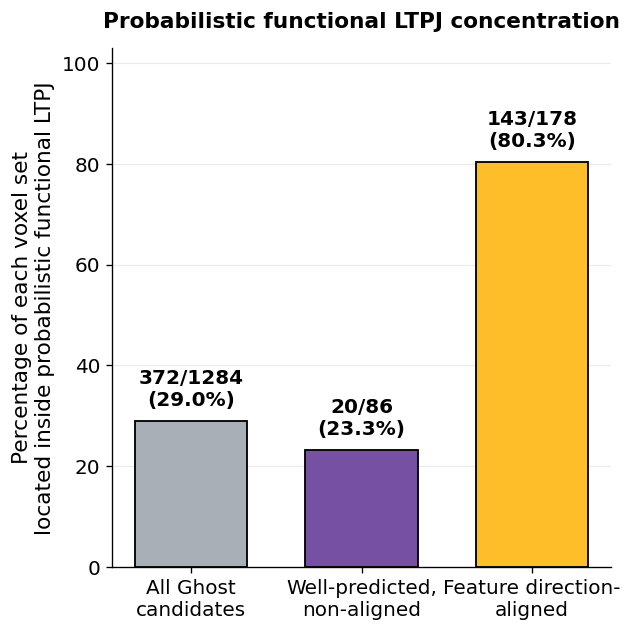

,TPJ reference,Voxel set,Inside,Total,Inside (%)
0,Probabilistic functional LTPJ,"Well-predicted, non-aligned",20,86,23.3
1,Probabilistic functional LTPJ,Feature direction-aligned,143,178,80.3
2,Anatomical PGi/TPOJ (Glasser),"Well-predicted, non-aligned",10,86,11.6
3,Anatomical PGi/TPOJ (Glasser),Feature direction-aligned,138,178,77.5


Skipping the functional-versus-Glasser comparison plot: optional Glasser assets unavailable.
Saved ghost_probabilistic_functional_ltpj_alignment_horizontal_2026-09-22.png and .pdf


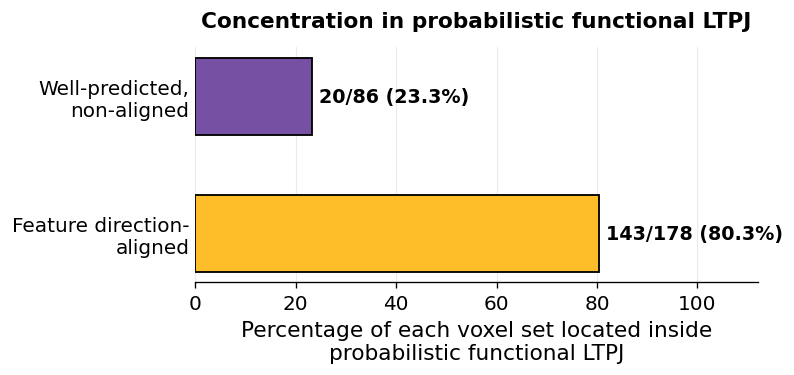

Saved ghost_probabilistic_functional_ltpj_alignment_vertical_2026-09-22.png and .pdf


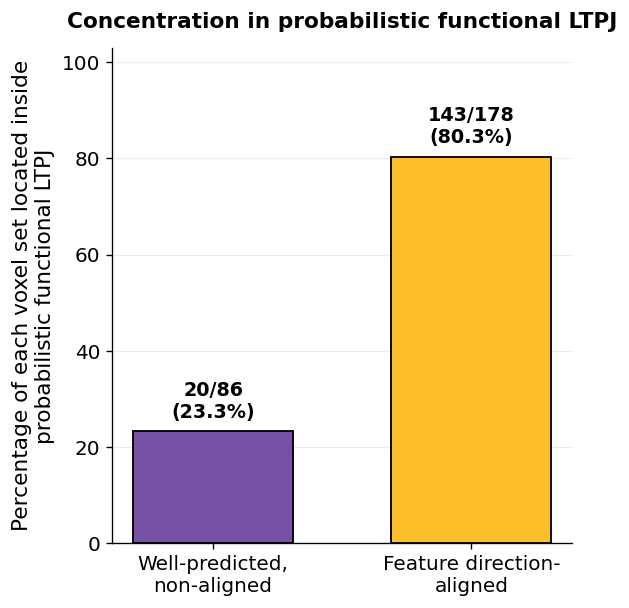

,Participant,"Well-predicted, non-aligned (%)",Feature direction-aligned (%),Non-aligned n,Aligned n
0,p1,41.4,87.9,29,58
1,p2,22.2,86.5,9,74
2,p3,0.0,0.0,3,9
3,p5,8.3,33.3,24,12
4,p8,19.0,96.0,21,25


Saved ghost_functional_ltpj_quantification_participants_2026-09-22.png and .pdf


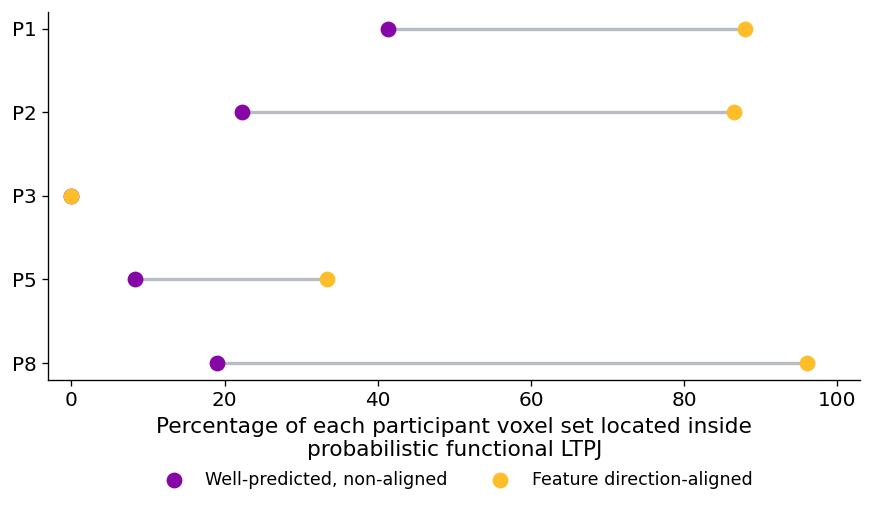

In [16]:
FIGURE_DIR = REPO_ROOT / "analysis/figures"

quantification_rows = []
for label, frame in [
    ("All Ghost\ncandidates", core_ghost),
    ("Well-predicted,\nnon-aligned", core_well_nonaligned),
    ("Feature direction-\naligned", core_aligned),
]:
    inside = int(frame["Inside Saxe functional LTPJ"].sum())
    quantification_rows.append({
        "Voxel set": label.replace("\n", " "),
        "Total": len(frame),
        "Inside probabilistic functional LTPJ": inside,
        "Inside probabilistic functional LTPJ (%)": 100 * inside / len(frame),
    })
functional_ltpj_quantification = pd.DataFrame(quantification_rows)
display(
    functional_ltpj_quantification.style.format(
        {"Inside probabilistic functional LTPJ (%)": "{:.1f}"}
    )
)
functional_ltpj_quantification.to_csv(
    FIGURE_DIR / "ghost_functional_ltpj_quantification.csv", index=False
)

# Option 1 (recommended): direct percentage bars.
labels = [
    "All Ghost\ncandidates",
    "Well-predicted,\nnon-aligned",
    "Feature direction-\naligned",
]
percentages = functional_ltpj_quantification[
    "Inside probabilistic functional LTPJ (%)"
].to_numpy()
inside_counts = functional_ltpj_quantification[
    "Inside probabilistic functional LTPJ"
].to_numpy()
totals = functional_ltpj_quantification["Total"].to_numpy()
bar_colors = ["#A9AFB7", "#7651A3", agreement_cmap(0.86)]

fig, ax = plt.subplots(figsize=(5.4, 5.4))
bars = ax.bar(
    np.arange(3), percentages, color=bar_colors, width=0.66,
    edgecolor="black", linewidth=1.1, zorder=3,
)
for bar, pct, inside, total in zip(bars, percentages, inside_counts, totals):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        pct + 2.2,
        f"{inside}/{total}\n({pct:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold",
    )
ax.set_xticks(np.arange(3), labels)
ax.set_ylabel(
    "Percentage of each voxel set\nlocated inside probabilistic functional LTPJ"
)
ax.set_ylim(0, 103)
ax.set_yticks(np.arange(0, 101, 20))
ax.set_title(
    "Probabilistic functional LTPJ concentration",
    fontweight="bold",
    pad=12,
)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(colors="black")
ax.yaxis.grid(True, linewidth=0.7, alpha=0.25, zorder=0)
fig.tight_layout()
save_figure(
    fig, FIGURE_DIR / "ghost_functional_ltpj_quantification_bar_2026-09-22"
)
plt.show()

# Option 2: add the anatomical comparison only when its assets are available.
reference_specs = [
    ("Probabilistic\nfunctional LTPJ", "Inside Saxe functional LTPJ"),
]
if GLASSER_AVAILABLE:
    for frame in (core_well_nonaligned, core_aligned):
        frame["Inside Glasser PGi/TPOJ"] = glasser_tpj_surface[
            frame["neuroid"].astype(int).to_numpy()
        ]
    reference_specs.append(("Anatomical PGi/TPOJ\n(Glasser)", "Inside Glasser PGi/TPOJ"))
tpj_reference_rows = []
for reference_label, column in reference_specs:
    for voxel_set, frame in [
        ("Well-predicted, non-aligned", core_well_nonaligned),
        ("Feature direction-aligned", core_aligned),
    ]:
        inside = int(frame[column].sum())
        tpj_reference_rows.append({
            "TPJ reference": reference_label.replace("\n", " "),
            "Voxel set": voxel_set,
            "Inside": inside,
            "Total": len(frame),
            "Inside (%)": 100 * inside / len(frame),
        })
tpj_reference_quantification = pd.DataFrame(tpj_reference_rows)
display(tpj_reference_quantification.style.format({"Inside (%)": "{:.1f}"}))
tpj_reference_quantification.to_csv(
    FIGURE_DIR / "ghost_tpj_reference_alignment_quantification.csv",
    index=False,
)

reference_labels = [label for label, _ in reference_specs]
nonaligned_pct = np.array([
    100 * core_well_nonaligned[column].mean()
    for _, column in reference_specs
])
aligned_pct = np.array([
    100 * core_aligned[column].mean()
    for _, column in reference_specs
])

if GLASSER_AVAILABLE:
    fig, ax = plt.subplots(figsize=(7.2, 4.2))
    y = np.arange(len(reference_specs))
    bar_height = 0.30
    nonaligned_bars = ax.barh(
        y + bar_height / 1.7,
        nonaligned_pct,
        height=bar_height,
        color="#7651A3",
        edgecolor="black",
        linewidth=1.1,
        label="Well-predicted, non-aligned",
        zorder=3,
    )
    aligned_bars = ax.barh(
        y - bar_height / 1.7,
        aligned_pct,
        height=bar_height,
        color=agreement_cmap(0.86),
        edgecolor="black",
        linewidth=1.1,
        label="Feature direction-aligned",
        zorder=3,
    )
    for bars, values in [
        (nonaligned_bars, nonaligned_pct),
        (aligned_bars, aligned_pct),
    ]:
        for bar, pct in zip(bars, values):
            ax.text(
                pct + 1.4,
                bar.get_y() + bar.get_height() / 2,
                f"{pct:.1f}%",
                ha="left",
                va="center",
                fontsize=11.5,
                fontweight="bold",
            )
    ax.set_yticks(y, reference_labels)
    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.set_xticks(np.arange(0, 101, 20))
    ax.set_xlabel("Percentage of each voxel set located inside TPJ")
    ax.set_title(
        "TPJ concentration by feature-direction alignment",
        fontweight="bold",
        pad=12,
    )
    ax.legend(
        frameon=False, ncol=2, loc="lower center",
        bbox_to_anchor=(0.5, -0.38), fontsize=10.5,
    )
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(axis="y", length=0, colors="black")
    ax.tick_params(axis="x", colors="black")
    ax.xaxis.grid(True, linewidth=0.7, alpha=0.25, zorder=0)
    fig.subplots_adjust(left=0.28, right=0.98, top=0.84, bottom=0.25)
    save_figure(
        fig,
        FIGURE_DIR / "ghost_tpj_reference_alignment_comparison_2026-09-22",
    )
    plt.show()
else:
    print("Skipping the functional-versus-Glasser comparison plot: optional Glasser assets unavailable.")

# Option 2b: the primary probabilistic functional LTPJ contrast by itself.
functional_labels = [
    "Well-predicted,\nnon-aligned",
    "Feature direction-\naligned",
]
functional_pct = np.array([nonaligned_pct[0], aligned_pct[0]])
functional_inside = np.array([
    int(core_well_nonaligned["Inside Saxe functional LTPJ"].sum()),
    int(core_aligned["Inside Saxe functional LTPJ"].sum()),
])
functional_totals = np.array([
    len(core_well_nonaligned),
    len(core_aligned),
])

fig, ax = plt.subplots(figsize=(6.6, 3.5))
y = np.arange(2)
bars = ax.barh(
    y,
    functional_pct,
    height=0.56,
    color=["#7651A3", agreement_cmap(0.86)],
    edgecolor="black",
    linewidth=1.1,
    zorder=3,
)
for bar, pct, inside, total in zip(
    bars, functional_pct, functional_inside, functional_totals
):
    ax.text(
        pct + 1.4,
        bar.get_y() + bar.get_height() / 2,
        f"{inside}/{total} ({pct:.1f}%)",
        ha="left",
        va="center",
        fontsize=11.5,
        fontweight="bold",
    )
ax.set_yticks(y, functional_labels)
ax.invert_yaxis()
ax.set_xlim(0, 112)
ax.set_xticks(np.arange(0, 101, 20))
ax.set_xlabel(
    "Percentage of each voxel set located inside\n"
    "probabilistic functional LTPJ"
)
ax.set_title(
    "Concentration in probabilistic functional LTPJ",
    fontweight="bold",
    pad=12,
)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0, colors="black")
ax.tick_params(axis="x", colors="black")
ax.xaxis.grid(True, linewidth=0.7, alpha=0.25, zorder=0)
fig.subplots_adjust(left=0.27, right=0.98, top=0.81, bottom=0.25)
save_figure(
    fig,
    FIGURE_DIR
    / "ghost_probabilistic_functional_ltpj_alignment_horizontal_2026-09-22",
)
plt.show()

# Matching vertical version of the primary two-group contrast.
fig, ax = plt.subplots(figsize=(5.0, 5.2))
x = np.arange(2)
bars = ax.bar(
    x,
    functional_pct,
    width=0.62,
    color=["#7651A3", agreement_cmap(0.86)],
    edgecolor="black",
    linewidth=1.1,
    zorder=3,
)
for bar, pct, inside, total in zip(
    bars, functional_pct, functional_inside, functional_totals
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        pct + 2.0,
        f"{inside}/{total}\n({pct:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=11.5,
        fontweight="bold",
    )
ax.set_xticks(x, functional_labels)
ax.set_ylim(0, 103)
ax.set_yticks(np.arange(0, 101, 20))
ax.set_ylabel(
    "Percentage of each voxel set located inside\n"
    "probabilistic functional LTPJ"
)
ax.set_title(
    "Concentration in probabilistic functional LTPJ",
    fontweight="bold",
    pad=12,
)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(colors="black")
ax.yaxis.grid(True, linewidth=0.7, alpha=0.25, zorder=0)
fig.tight_layout()
save_figure(
    fig,
    FIGURE_DIR
    / "ghost_probabilistic_functional_ltpj_alignment_vertical_2026-09-22",
)
plt.show()

# Option 3: participant-resolved paired percentages.
participant_quantification = []
for participant in ANATOMY_PARTICIPANTS:
    participant_non = core_well_nonaligned[
        core_well_nonaligned["Participant"].eq(participant)
    ]
    participant_aligned = core_aligned[
        core_aligned["Participant"].eq(participant)
    ]
    participant_quantification.append({
        "Participant": participant,
        "Well-predicted, non-aligned (%)": (
            100 * participant_non["Inside Saxe functional LTPJ"].mean()
        ),
        "Feature direction-aligned (%)": (
            100 * participant_aligned["Inside Saxe functional LTPJ"].mean()
        ),
        "Non-aligned n": len(participant_non),
        "Aligned n": len(participant_aligned),
    })
participant_quantification = pd.DataFrame(participant_quantification)
display(participant_quantification.style.format({
    "Well-predicted, non-aligned (%)": "{:.1f}",
    "Feature direction-aligned (%)": "{:.1f}",
}))

fig, ax = plt.subplots(figsize=(7.4, 4.5))
y = np.arange(len(participant_quantification))
for yi, row in participant_quantification.iterrows():
    ax.plot(
        [row["Well-predicted, non-aligned (%)"],
         row["Feature direction-aligned (%)"]],
        [yi, yi], color="#B8BDC4", linewidth=2.0, zorder=1,
    )
ax.scatter(
    participant_quantification["Well-predicted, non-aligned (%)"], y,
    s=72, color=agreement_cmap(0.27), label="Well-predicted, non-aligned",
    zorder=2,
)
ax.scatter(
    participant_quantification["Feature direction-aligned (%)"], y,
    s=72, color=agreement_cmap(0.86), label="Feature direction-aligned",
    zorder=3,
)
ax.set_yticks(y, participant_quantification["Participant"].str.upper())
ax.invert_yaxis()
ax.set_xlim(-3, 103)
ax.set_xlabel(
    "Percentage of each participant voxel set located inside\n"
    "probabilistic functional LTPJ"
)
ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, -0.34),
          ncol=2, fontsize=10.5)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(colors="black")
fig.tight_layout()
save_figure(
    fig,
    FIGURE_DIR / "ghost_functional_ltpj_quantification_participants_2026-09-22",
)
plt.show()


## Supplement: individual-participant surface maps

Each participant is shown separately using the identical surface, outlines,
marker sizes, prediction threshold, and Plasma normalization as the primary
group map. This preserves participant identity while making the spatial
convergence directly inspectable.

Saved ghost_surface_participants_plasma_functional_ltpj_supplement_2026-09-22.png and .pdf


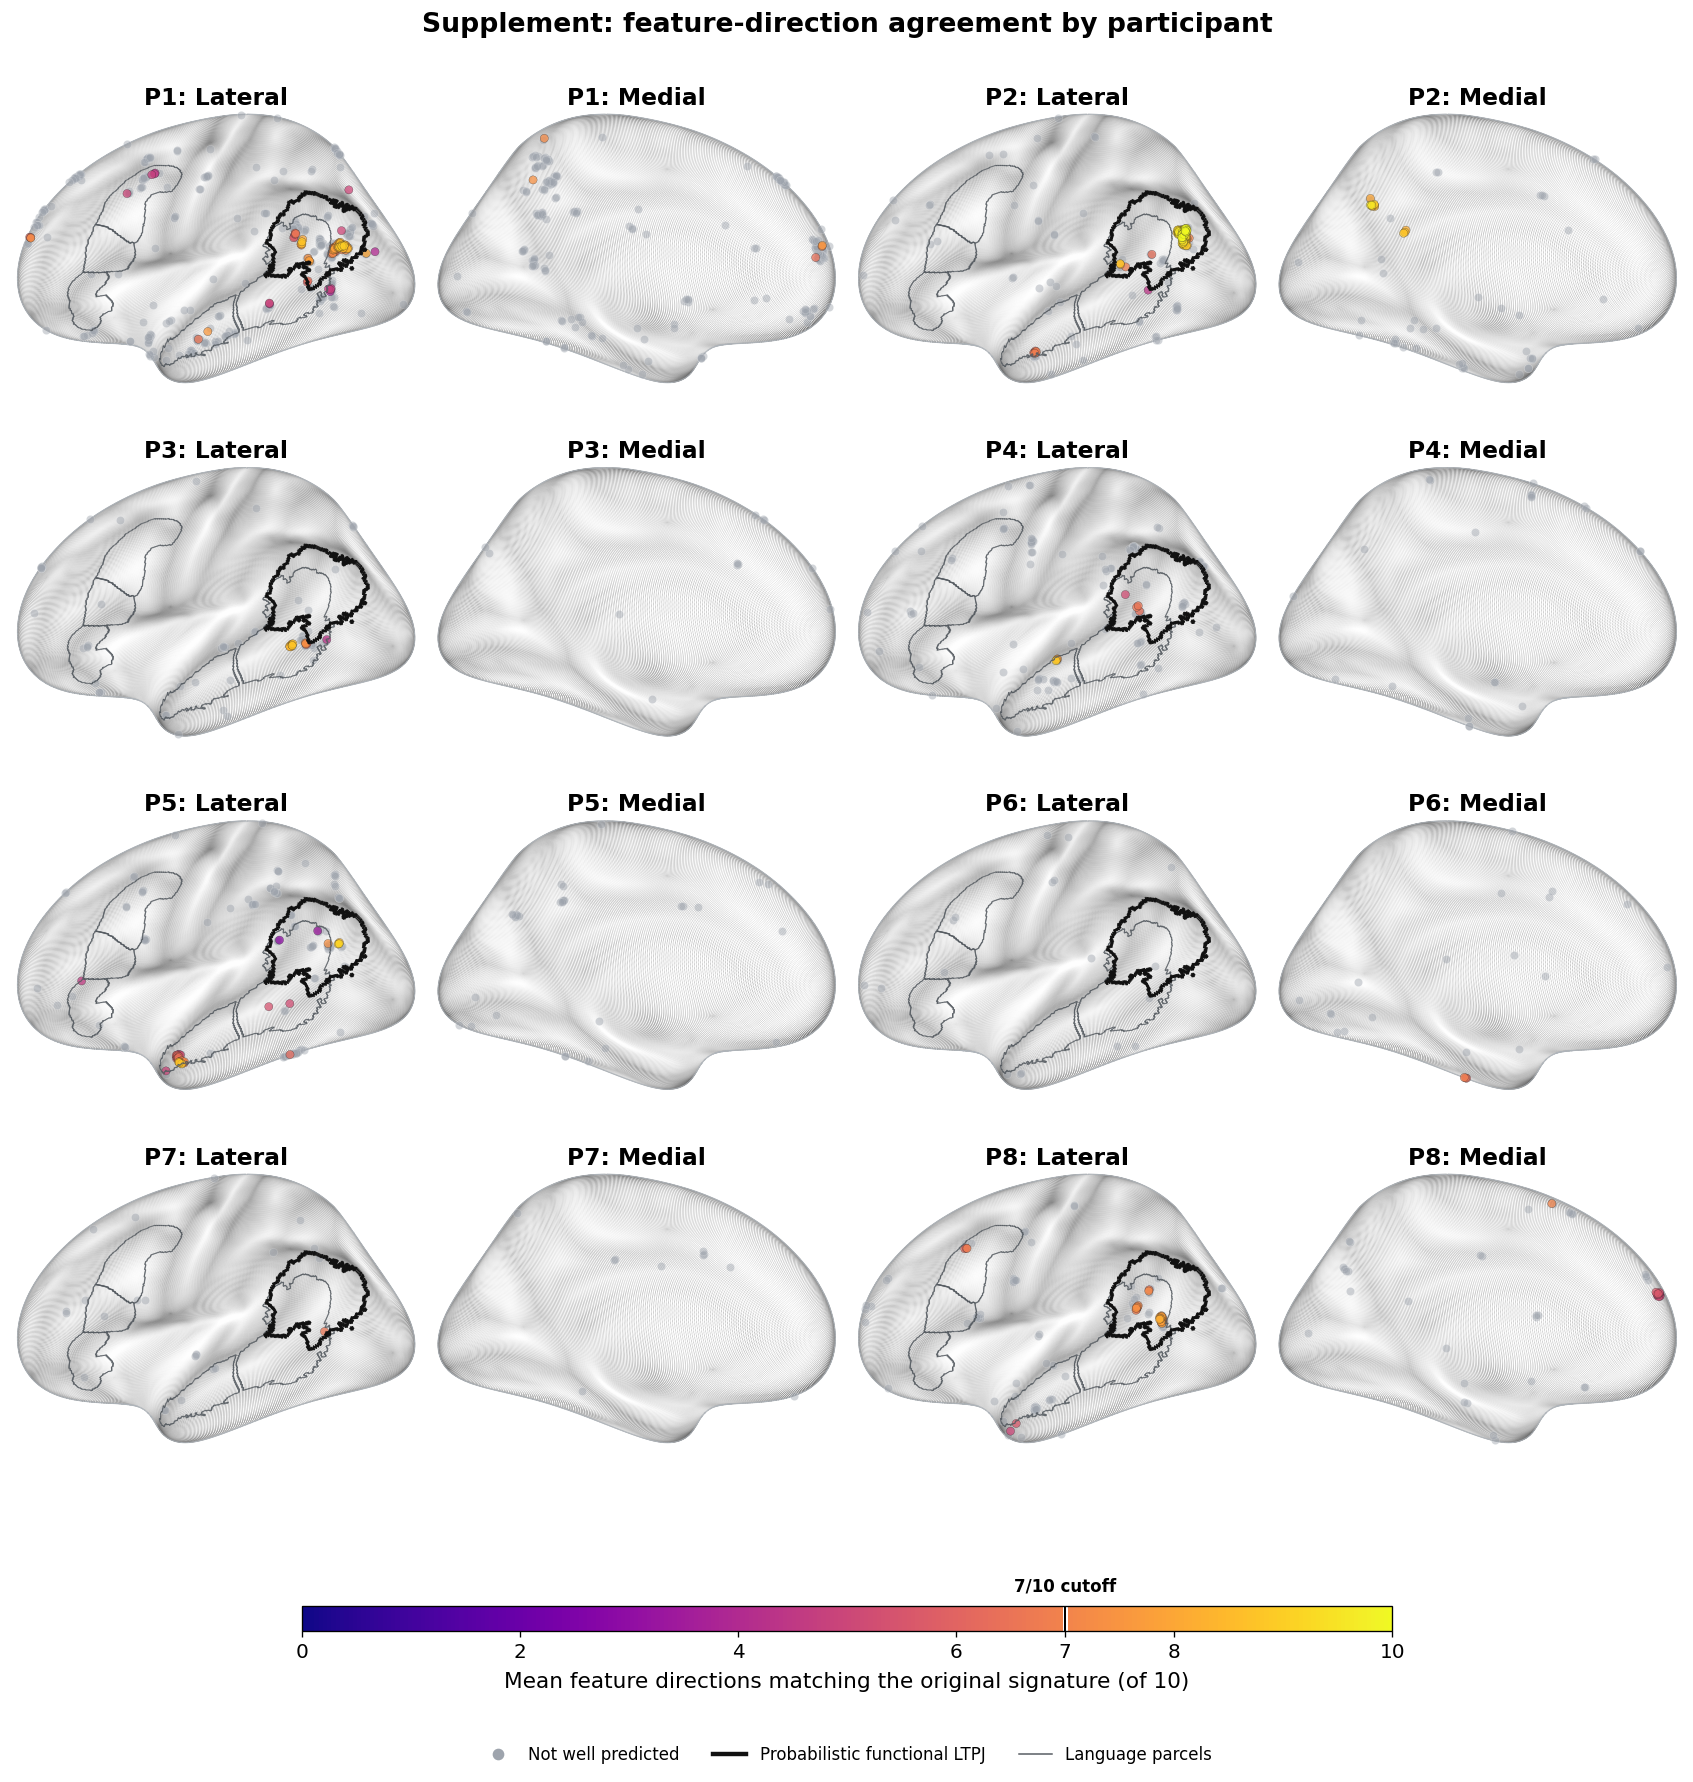

In [17]:
fig, axes = plt.subplots(4, 4, figsize=(14.2, 14.8))
for participant_index, participant in enumerate(PARTICIPANTS):
    row = participant_index // 2
    first_column = 2 * (participant_index % 2)
    participant_frame = ghost[ghost["Participant"].eq(participant)]
    for offset, view in enumerate(["lateral", "medial"]):
        ax = axes[row, first_column + offset]
        prepare_brain_axis(
            ax,
            view,
            reference="saxe",
            title=f"{participant.upper()}: {view.capitalize()}",
        )
        plot_gray_and_agreement(ax, participant_frame, view)

fig.subplots_adjust(
    left=0.01, right=0.99, top=0.96, bottom=0.17, hspace=0.03, wspace=0.03
)
add_agreement_colorbar(
    fig, axes, bounds=[0.18, 0.085, 0.64, 0.014]
)
fig.legend(
    handles=reference_legend("saxe"),
    loc="lower center",
    bbox_to_anchor=(0.5, 0.002),
    frameon=False,
    ncol=3,
    fontsize=10,
)
fig.suptitle(
    "Supplement: feature-direction agreement by participant",
    fontsize=16,
    fontweight="bold",
    y=0.997,
)
participant_surface_stem = (
    FIGURE_DIR
    / "ghost_surface_participants_plasma_functional_ltpj_"
      "supplement_2026-09-22"
)
save_figure(fig, participant_surface_stem)
plt.show()


## Supplement: anatomical Glasser PGi/TPOJ reference

This supplement repeats the primary group display while changing only the
black reference outline to the anatomical Glasser union of PGi and
TPOJ1/2/3. The compact table provides the corresponding composition; the
probabilistic functional LTPJ parcel remains the primary anatomical
quantification.

,Voxel set,Total,Inside Glasser PGi/TPOJ,Inside Glasser PGi/TPOJ (%)
0,All additional Ghost candidates,1284,315,24.5
1,Well-predicted but non-aligned,86,10,11.6
2,Well-predicted and aligned,178,138,77.5


Saved ghost_surface_agreement_plasma_glasser_pgi_tpoj_supplement_2026-09-22.png and .pdf


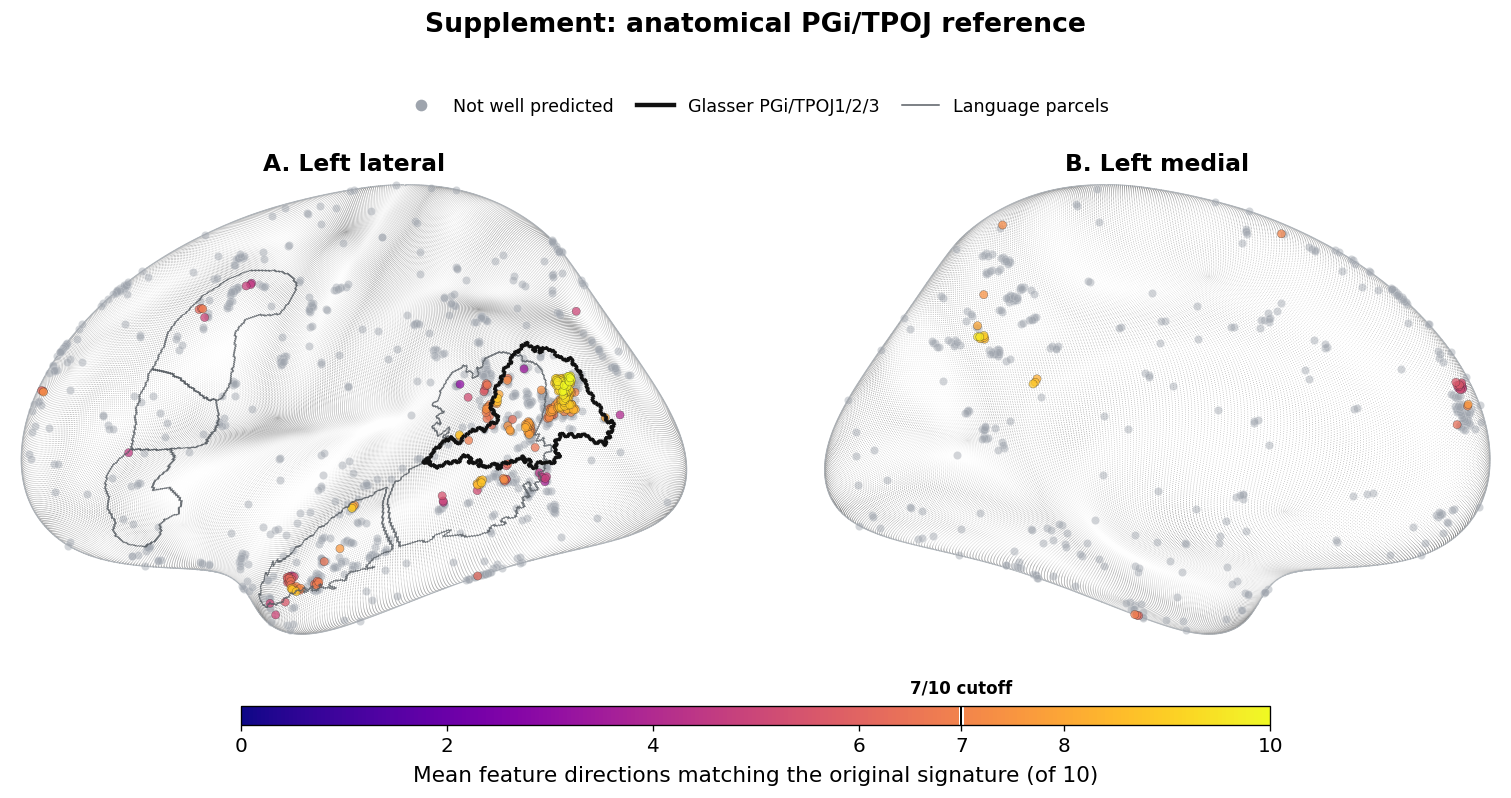

In [18]:
if GLASSER_AVAILABLE:
    for frame in (core_ghost, core_well_nonaligned, core_aligned):
        frame["Inside Glasser PGi/TPOJ"] = glasser_tpj_surface[
            frame["neuroid"].astype(int).to_numpy()
        ]

    glasser_rows = []
    for label, frame in [
        ("All additional Ghost candidates", core_ghost),
        ("Well-predicted but non-aligned", core_well_nonaligned),
        ("Well-predicted and aligned", core_aligned),
    ]:
        inside = int(frame["Inside Glasser PGi/TPOJ"].sum())
        glasser_rows.append({
            "Voxel set": label,
            "Total": len(frame),
            "Inside Glasser PGi/TPOJ": inside,
            "Inside Glasser PGi/TPOJ (%)": 100 * inside / len(frame),
        })
    glasser_composition = pd.DataFrame(glasser_rows)
    display(
        glasser_composition.style.format(
            {"Inside Glasser PGi/TPOJ (%)": "{:.1f}"}
        )
    )

    glasser_surface_stem = (
        FIGURE_DIR
        / "ghost_surface_agreement_plasma_"
          "glasser_pgi_tpoj_supplement_2026-09-22"
    )
    make_group_surface(
        "glasser",
        "Supplement: anatomical PGi/TPOJ reference",
        glasser_surface_stem,
    )
else:
    print("Skipping the Glasser surface supplement and surface-based table: optional Glasser assets unavailable.")


## Original 20-per-participant Ghost set

The held-out search excludes the original Ghost voxels. For anatomical
context, we reconstruct the Study 2 hierarchical ordering of the original 160
Ghost voxels and identify the original 32-voxel discovery cluster using the
same fixed matrix interval (positions 70–101 inclusive). The map uses the same
probabilistic functional LTPJ and language-parcel outlines as the primary
extension map.

Saved ghost_surface_original_160_functional_ltpj_2026-09-22.png and .pdf


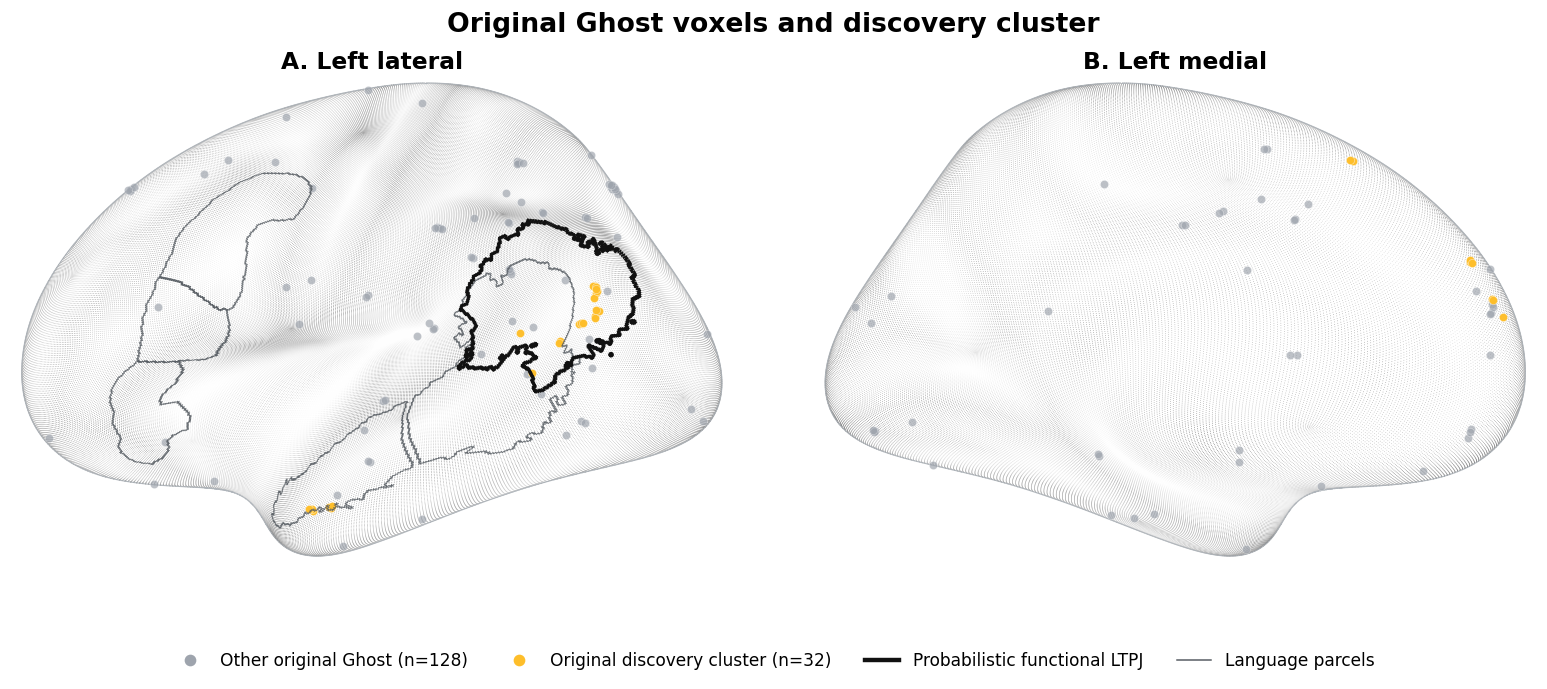

In [19]:
if str(REPO_ROOT / "analysis") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "analysis"))
import generalization_utils

ORIGINAL_GHOST_GENERALIZATION = (
    PUBLIC_REPO
    / "results_anon/categories/full_features/generalization_8000/sae/"
      "gemma-2-2b-res-matryoshka-dc/mean/12/standardized_betas/"
      "generalization/ghost.csv"
)
original_generalization = pd.read_csv(ORIGINAL_GHOST_GENERALIZATION)
_, original_ghost_order = generalization_utils.run_cluster_generalization_analysis(
    original_generalization
)
original_cluster_keys = set(original_ghost_order[70:102])

original_frames = []
for participant in PARTICIPANTS:
    path = PUBLIC_REPO / f"data/processed_csvs_anon/{participant}/ghost_meta.csv"
    frame = pd.read_csv(path)
    frame["Participant"] = participant
    frame["neuroid"] = validated_vertices(frame["neuroid_id"])
    frame["Voxel key"] = participant + "_" + frame["neuroid"].astype(str)
    original_frames.append(frame)
original_ghost = pd.concat(original_frames, ignore_index=True)
original_ghost["Original 32-voxel cluster"] = original_ghost[
    "Voxel key"
].isin(original_cluster_keys)

assert len(original_ghost) == 160
assert original_ghost.groupby("Participant").size().eq(20).all()
assert int(original_ghost["Original 32-voxel cluster"].sum()) == 32


def plot_original_ghost(ax, view):
    geometry = view_geometry[view]
    visible = geometry["visible"]
    x_coordinates, y_coordinates = geometry["x"], geometry["y"]
    for is_cluster, color, alpha, zorder in [
        (False, GRAY_GHOST, 0.68, 2),
        (True, agreement_cmap(0.86), 0.98, 3),
    ]:
        layer = original_ghost[
            original_ghost["Original 32-voxel cluster"].eq(is_cluster)
        ]
        vertices = layer["neuroid"].astype(int).to_numpy()
        vertices = vertices[visible[vertices]]
        ax.scatter(
            x_coordinates[vertices],
            y_coordinates[vertices],
            s=MARKER_AREA,
            color=color,
            alpha=alpha,
            edgecolors="white",
            linewidths=0.22,
            rasterized=True,
            zorder=zorder,
        )


fig, axes = plt.subplots(1, 2, figsize=(13.4, 5.7))
for ax, view, panel in zip(
    axes,
    ["lateral", "medial"],
    ["A. Left lateral", "B. Left medial"],
):
    prepare_brain_axis(ax, view, reference="saxe", title=panel)
    plot_original_ghost(ax, view)

original_legend = [
    Line2D([0], [0], marker="o", linestyle="none", color=GRAY_GHOST,
           label="Other original Ghost (n=128)", markersize=6),
    Line2D([0], [0], marker="o", linestyle="none",
           color=agreement_cmap(0.86),
           label="Original discovery cluster (n=32)", markersize=6),
]
original_legend.extend(reference_legend("saxe")[1:])
fig.legend(
    handles=original_legend,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.005),
    frameon=False,
    ncol=4,
    fontsize=10.2,
)
fig.suptitle(
    "Original Ghost voxels and discovery cluster",
    fontsize=16,
    fontweight="bold",
    y=0.99,
)
fig.subplots_adjust(left=0.01, right=0.99, top=0.90, bottom=0.18, wspace=0.04)
original_surface_stem = (
    FIGURE_DIR / "ghost_surface_original_160_functional_ltpj_2026-09-22"
)
save_figure(fig, original_surface_stem)
plt.show()


### Reading the surface maps

The lateral and medial panels use identical fsaverage7 coordinates and marker
sizes. Gray points are eligible Ghost candidates that do not pass the primary
prediction screen; Plasma colors encode graded directional agreement only
among well-predicted voxels. The solid black outline is the independent
probabilistic functional LTPJ parcel in the primary maps, and thin dark-gray
outlines indicate the five language parcels. The participant-pooled map describes spatial
concentration in a common coordinate system; exact shared vertex IDs are
quantified separately above.